# 06 — Treinamento Escalável, Rastreamento MLflow, Explicabilidade SHAP e Serialização (`enem.pkl`)

**Projeto de TCC — MBA em Ciência de Dados & MLOps**  
**Autor:** Saulo Santos  

---

## 🎯 Papel Arquitetural deste Notebook

Este notebook encerra a **Etapa 1 (Laboratório Analítico, NLP e Modelagem)** do projeto e constrói a ponte direta para a **Etapa 2 (Produtização via FastAPI + Docker + GitHub Actions + AWS)** e para a **Etapa 3 (Orquestração Apache Airflow + Validação *Out-of-Time* no ENEM 2024)**:

```text
[01_investigacao] ──> [02_eda (2023)] ──> [03_features (2023)] ──> [04_nlp_sbert (2009–2025)]
                                                                               │
                                                                               ▼
   Etapa 2 (FastAPI/Docker/AWS) <── models/enem.pkl <── [06_treinamento_modelo] <── [05_consolidacao (37,59M)]
```

### Escopo Científico e de Engenharia MLOps
Alimentado pelo censo histórico unificado de **10 edições da Década de Ouro (`2014` a `2023` — `37.593.629` candidatos presentes, `537,78 MB` em RAM)** gerado no Notebook 05, este notebook executa um protocolo rigoroso em **3 Estágios Escaláveis**:

| Componente | Especificação Homologada | Justificativa Metodológica / MLOps |
| :--- | :--- | :--- |
| **Alvo Oficial (`y`)** | `TARGET_M4` (`float32`, `[0, 1000]`) | Média aritmética das 4 provas objetivas da TRI ($\alpha_{\text{Cronbach}} = 0.865$), livre do ruído subjetivo da Redação. |
| **Esquadrão de Elite (`X`)** | `RENDA_PER_CAPITA`, `Q024`, `TP_ANO_CONCLUIU`, `TP_LINGUA`, `TP_SEXO`, `Q002` | Parcimônia de Ockham: 6 preditores socioeconômicos deflacionados e harmonizados (`9 bytes/linha` em `X`). |
| **Partição de Dados** | **80% Desenvolvimento / 20% Holdout** estratificado por `NU_ANO` + **Rodada *Out-of-Time* (`2014–2022 -> 2023`)** | Garante avaliação cega em `~7,52 milhões` de alunos de toda a década e prova resiliência temporal antes de 2024. |
| **Modelos Concorrentes** | *Dummy* $\times$ *Ridge* $\times$ ***Random Forest*** (*Bagging*) $\times$ ***XGBoost*** (*Boosting* `hist`) | Competição justa sob os mesmos 5 folds estratificados, seguida de *Tuning*, Curva de Aprendizado e Treino Censitário. |
| **Governança & XAI** | **MLflow 3.x** (`sqlite:///mlflow.db`) + **TreeSHAP** + **`models/enem.pkl`** | Rastreabilidade integral de hiperparâmetros/artefatos, prova sociológica marginal (Bourdieu) e modelo pronto para API REST. |

> **Documentação Complementar:** Consulte o guia detalhado [`passo-a-passo-06.md`](../passo-a-passo-06.md) na raiz do repositório para instruções de execução, interpretação estatística, abertura do painel visual do **MLflow UI** e checklist de validação.

---
## 1. Configuração do Ambiente, Telemetria de Hardware/RAM e Inicialização do MLflow

### O que esta célula faz?
Prepara toda a infraestrutura computacional e de governança MLOps do notebook dividida em **5 blocos modulares**:
* **Bloco 1.1 (Importações):** Carrega a pilha científica (`numpy`, `pandas`, `scikit-learn`, `xgboost`, `shap`, `matplotlib`, `seaborn`) e as bibliotecas de rastreabilidade e serialização (`mlflow`, `pickle`, `joblib`, `hashlib`, `psutil`).
* **Bloco 1.2 (Reprodutibilidade e Paralelismo Consciente):** Fixa `SEED = 42` e detecta os núcleos físicos e lógicos da CPU para paralelizar internamente as árvores sem duplicar matrizes em processos externos.
* **Bloco 1.3 (Resolução Resiliente de Diretórios):** Localiza automaticamente a raiz do repositório (`enem/`) e cria as pastas `models/`, `mlruns/` e `media/nb06_figuras/`.
* **Bloco 1.4 (Funções Utilitárias de Memória, Inferência em Lotes e Métricas):** Define `obter_telemetria_ram()`, `prever_em_blocos()` (que executa predições em fatias de `1.000.000` de linhas para manter o custo de RAM irrisório ao avaliar `7,52 milhões` de candidatos) e `calcular_metricas_regressao()` ($R^2$, $\text{RMSE}$, $\text{MAE}$ e Erro Relativo $\text{RMSE}/\sigma$).
* **Bloco 1.5 (Servidor Relacional Local do MLflow):** Configura o backend oficial em SQLite (`sqlite:///mlflow.db`) com armazenamento de artefatos em `./mlruns` e inicializa o experimento `tcc_enem_decada_ouro_2014_2023`.

In [1]:
# ==============================================================================
# SEÇÃO 1: CONFIGURAÇÃO DO AMBIENTE, TELEMETRIA E INICIALIZAÇÃO DO MLFLOW
# ==============================================================================

# ── Bloco 1.1: Importação organizada da pilha científica e de MLOps ───────────
from datetime import datetime, timezone
import gc
import hashlib
import json
import os
from pathlib import Path
import pickle
import sys
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import mlflow
from mlflow.models import infer_signature
import mlflow.sklearn
import mlflow.xgboost
import numpy as np
import pandas as pd
import psutil
import pyarrow as pa
import seaborn as sns
import shap
import sklearn
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import StratifiedKFold, cross_validate
import xgboost as xgb
from xgboost import XGBRegressor

# Suprime avisos benignos de schema inteiro do MLflow (nossas features int8 não possuem NaNs por contrato)
warnings.filterwarnings("ignore", message=".*Inferred schema contains integer column.*")

# ── Bloco 1.2: Semente determinística, paralelismo de CPU e padrão visual ─────
SEED = 42
np.random.seed(SEED)

N_THREADS_LOGICAS = os.cpu_count() or 4
N_THREADS_FISICAS = psutil.cpu_count(logical=False) or max(1, N_THREADS_LOGICAS // 2)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["figure.dpi"] = 120


# ── Bloco 1.3: Resolução automática da raiz do projeto e estrutura de pastas ──
def localizar_raiz_projeto() -> Path:
    """
    Sobe na árvore de diretórios até localizar a raiz do repositório 'enem/',
    garantindo execução idempotente em qualquer diretório de trabalho do Jupyter.
    """
    atual = Path.cwd().resolve()
    for candidato in [atual] + list(atual.parents):
        if (candidato / "data" / "processed").exists() and (candidato / "notebooks").exists():
            return candidato
    raise FileNotFoundError(
        "Raiz do projeto não encontrada! Verifique se 'data/processed' e 'notebooks' existem."
    )


PROJECT_ROOT = localizar_raiz_projeto()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
CHECKPOINT_SAFRAS_DIR = PROCESSED_DIR / "safras_consolidacao"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR = PROJECT_ROOT / "media" / "nb06_figuras"
MLFLOW_ARTIFACTS_DIR = PROJECT_ROOT / "mlruns"
MLFLOW_DB_PATH = PROJECT_ROOT / "mlflow.db"

for pasta in (MODELS_DIR, FIGURES_DIR, MLFLOW_ARTIFACTS_DIR):
    pasta.mkdir(parents=True, exist_ok=True)

# Contratos de entrada (Notebook 05) e artefatos finais de saída (Etapa 2 / AWS)
CAMINHO_PARQUET_CONSOLIDADO = PROCESSED_DIR / "enem_2014_2023_consolidado.parquet"
CAMINHO_CONTRATO_NB05 = PROCESSED_DIR / "contrato_consolidacao_2014_2023.json"
CAMINHO_MODELO_PKL = MODELS_DIR / "enem.pkl"
CAMINHO_MODELO_UBJ = MODELS_DIR / "enem_xgboost.ubj"
CAMINHO_MODEL_CARD = MODELS_DIR / "enem_model_card.json"


# ── Bloco 1.4: Utilitários de telemetria RAM, predição em lotes e métricas ────
def obter_telemetria_ram() -> dict:
    """Retorna o uso atual de memória física (RSS) do kernel e a folga do host."""
    proc = psutil.Process(os.getpid())
    vm = psutil.virtual_memory()
    return {
        "processo_rss_mb": round(proc.memory_info().rss / (1024 ** 2), 2),
        "sistema_disponivel_gb": round(vm.available / (1024 ** 3), 2),
        "sistema_total_gb": round(vm.total / (1024 ** 3), 2),
        "sistema_uso_pct": round(vm.percent, 1),
    }


def prever_em_blocos(
    modelo,
    df_fonte: pd.DataFrame,
    colunas_x: list[str],
    batch_size: int = 1_000_000,
) -> np.ndarray:
    """
    Executa model.predict() em fatias controladas (padrão: 1 milhão de linhas).
    Evita picos desnecessários de RAM ao inferir sobre milhões de registros em CPU.
    """
    n_total = len(df_fonte)
    predicoes = np.empty(n_total, dtype=np.float32)
    for inicio in range(0, n_total, batch_size):
        fim = min(inicio + batch_size, n_total)
        bloco_x = df_fonte.iloc[inicio:fim][colunas_x]
        predicoes[inicio:fim] = np.asarray(modelo.predict(bloco_x), dtype=np.float32)
    return predicoes


def calcular_metricas_regressao(y_real: np.ndarray, y_pred: np.ndarray) -> dict:
    """
    Calcula o quarteto canônico de métricas de regressão do TCC:
      - R2                 : Proporção da variância da nota explicada pela origem social;
      - RMSE               : Erro quadrático médio na escala TRI (0 a 1000 pontos);
      - MAE                : Erro absoluto médio em pontos da TRI;
      - erro_relativo_sigma: Razão RMSE / DP(y_real), comparável entre edições distintas.
    """
    r2 = float(r2_score(y_real, y_pred))
    rmse = float(root_mean_squared_error(y_real, y_pred))
    mae = float(mean_absolute_error(y_real, y_pred))
    sigma_y = float(np.std(y_real))
    erro_rel = float(rmse / sigma_y) if sigma_y > 0 else np.nan
    return {
        "r2": round(r2, 5),
        "rmse": round(rmse, 4),
        "mae": round(mae, 4),
        "erro_relativo_sigma": round(erro_rel, 5),
    }


# ── Bloco 1.5: Inicialização do MLflow Tracking & Registry via SQLite ─────────
# Em POSIX, MLFLOW_DB_PATH.as_posix() já inicia com '/', formando 'sqlite:////caminho/mlflow.db'
MLFLOW_TRACKING_URI = f"sqlite:///{MLFLOW_DB_PATH.as_posix()}"
MLFLOW_EXPERIMENT_NAME = "tcc_enem_decada_ouro_2014_2023"
MLFLOW_REGISTERED_MODEL_NAME = "enem_target_m4_producao"

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
experimento_atual = mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT_NAME)
if experimento_atual is None:
    exp_id = mlflow.create_experiment(
        name=MLFLOW_EXPERIMENT_NAME,
        artifact_location=MLFLOW_ARTIFACTS_DIR.resolve().as_uri(),
        tags={
            "projeto": "TCC_MBA_Ciencia_Dados_MLOps",
            "autor": "Saulo Santos",
            "alvo_oficial": "TARGET_M4",
            "janela_historica": "2014-2023",
        },
    )
else:
    exp_id = experimento_atual.experiment_id

mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)
ram_boot = obter_telemetria_ram()

print("=" * 94)
print("AMBIENTE DE TREINAMENTO E GOVERNANÇA MLOPS INICIALIZADO COM SUCESSO")
print("=" * 94)
print(f"• Raiz do Repositório     : {PROJECT_ROOT}")
print(f"• Python & Hardware       : Python {sys.version.split()[0]} | {N_THREADS_FISICAS} cores físicos ({N_THREADS_LOGICAS} threads)")
print(
    f"• Versões da Pilha ML     : sklearn={sklearn.__version__} | xgboost={xgb.__version__} | "
    f"mlflow={mlflow.__version__} | shap={shap.__version__}"
)
print(f"• MLflow Tracking URI     : {MLFLOW_TRACKING_URI}")
print(f"• Experimento MLflow Ativo: {MLFLOW_EXPERIMENT_NAME} (ID={exp_id})")
print(
    f"• Telemetria Inicial RAM  : Processo={ram_boot['processo_rss_mb']:.1f} MB | "
    f"Disponível no Host={ram_boot['sistema_disponivel_gb']:.2f} GB / {ram_boot['sistema_total_gb']:.2f} GB"
)

/home/saulo/mba/tcc/enem/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/11/03 07:44:25 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/03 07:44:26 INFO mlflow.store.db.utils: Updating database tables


AMBIENTE DE TREINAMENTO E GOVERNANÇA MLOPS INICIALIZADO COM SUCESSO
• Raiz do Repositório     : /home/saulo/mba/tcc/enem
• Python & Hardware       : Python 3.13.9 | 4 cores físicos (8 threads)
• Versões da Pilha ML     : sklearn=1.9.0 | xgboost=3.4.1 | mlflow=3.17.2 | shap=0.54.1
• MLflow Tracking URI     : sqlite:////home/saulo/mba/tcc/enem/mlflow.db
• Experimento MLflow Ativo: tcc_enem_decada_ouro_2014_2023 (ID=1)
• Telemetria Inicial RAM  : Processo=373.0 MB | Disponível no Host=6.19 GB / 7.70 GB


---
## 2. Ingestão Auditada do Censo Consolidado (`2014–2023`) e Trava *Anti-Leakage*

### O que esta célula faz?
Carrega os artefatos gerados pelo **Notebook 05** aplicando validação criptográfica e contratual em **3 blocos**:
* **Bloco 2.1 (Validação do Contrato e Checksum `SHA-256`):** Lê `contrato_consolidacao_2014_2023.json` e recalcula em *streaming* o hash `SHA-256` de `enem_2014_2023_consolidado.parquet`, garantindo que nenhum byte foi corrompido ou alterado em disco.
* **Bloco 2.2 (Ingestão Colunar Ultrarrápida):** Carrega os `37.593.629` registros via `pyarrow` preservando rigorosamente o *downcasting* de `15 bytes/linha` (`~537,8 MB` em RAM).
* **Bloco 2.3 (Trava Formal *Anti-Leakage* e Metadados Semânticos):** Confirma as 6 features preditoras (`FEATURES_ELITE`), bloqueia formalmente a entrada de `NU_ANO` e `TARGET_M4` na matriz preditora `X` e declara os rótulos legíveis para os gráficos da dissertação.

In [2]:
# ==============================================================================
# SEÇÃO 2: INGESTÃO AUDITADA DO PARQUET CONSOLIDADO E TRAVA ANTI-LEAKAGE
# ==============================================================================
t0_ingest = time.perf_counter()

# ── Bloco 2.1: Leitura do contrato do Notebook 05 e verificação SHA-256 ───────
if not CAMINHO_PARQUET_CONSOLIDADO.exists() or not CAMINHO_CONTRATO_NB05.exists():
    raise FileNotFoundError(
        "Artefatos consolidados não encontrados em 'data/processed/'. "
        "Execute e valide o Notebook 05 antes de iniciar o Notebook 06."
    )

with open(CAMINHO_CONTRATO_NB05, "r", encoding="utf-8") as f_contrato:
    contrato_nb05 = json.load(f_contrato)

sha256_esperado = contrato_nb05["artefato_parquet"]["sha256"]
hasher = hashlib.sha256()
with open(CAMINHO_PARQUET_CONSOLIDADO, "rb") as f_bin:
    for bloco in iter(lambda: f_bin.read(8 * 1024 * 1024), b""):
        hasher.update(bloco)
sha256_calculado = hasher.hexdigest()

assert sha256_calculado == sha256_esperado, (
    f"Quebra de integridade no Parquet! Esperado={sha256_esperado}, Calculado={sha256_calculado}"
)

# ── Bloco 2.2: Carregamento colunar enxuto em memória RAM (15 bytes/linha) ────
df_decada = pd.read_parquet(CAMINHO_PARQUET_CONSOLIDADO, engine="pyarrow")

# ── Bloco 2.3: Extração do contrato de colunas e trava formal Anti-Leakage ────
COLUNA_PARTICAO_TEMPORAL = contrato_nb05["definicao_papel_colunas"]["coluna_particao_temporal"]["nome"]
FEATURES_ELITE = list(contrato_nb05["definicao_papel_colunas"]["features_ordenadas"])
ALVO_OFICIAL = contrato_nb05["definicao_papel_colunas"]["alvo_modelagem"]["nome"]
ANOS_HOMOLOGADOS = list(contrato_nb05["artefato_parquet"]["anos_incluidos"])

# Asserções defensivas inegociáveis
assert len(df_decada) == contrato_nb05["artefato_parquet"]["n_registros_totais"]
assert FEATURES_ELITE == [
    "RENDA_PER_CAPITA",
    "Q024",
    "TP_ANO_CONCLUIU",
    "TP_LINGUA",
    "TP_SEXO",
    "Q002",
], f"Ordem inesperada de features: {FEATURES_ELITE}"
assert COLUNA_PARTICAO_TEMPORAL not in FEATURES_ELITE, "Vazamento temporal: NU_ANO não pode entrar em X!"
assert ALVO_OFICIAL not in FEATURES_ELITE, "Target Leakage detectado: TARGET_M4 dentro de X!"
assert int(df_decada.isna().sum().sum()) == 0, "Valores ausentes detectados na base consolidada!"

# Rótulos descritivos para tabelas acadêmicas e gráficos SHAP da dissertação
ROTULOS_FEATURES = {
    "RENDA_PER_CAPITA": "Renda Per Capita (SM/morador)",
    "Q024": "Posse de Computador (0 a 3+)",
    "TP_ANO_CONCLUIU": "Anos desde Conclusão EM (0 a 9+)",
    "TP_LINGUA": "Língua Estrangeira (0=Ing, 1=Esp)",
    "TP_SEXO": "Sexo (0=Fem, 1=Masc)",
    "Q002": "Escolaridade Materna (0 a 7)",
}

ram_pos_ingest = obter_telemetria_ram()
ram_df_mb = df_decada.memory_usage(deep=True).sum() / (1024 ** 2)
bytes_linha = df_decada.memory_usage(deep=True).sum() / len(df_decada)

print("=" * 94)
print("CENSO CONSOLIDADO DA DÉCADA DE OURO AUDITADO E CARREGADO EM MEMÓRIA")
print("=" * 94)
print(f"• Integridade SHA-256     : OK ({sha256_calculado[:16]}...{sha256_calculado[-16:]})")
print(f"• Volume Carregado        : {len(df_decada):,} candidatos × {df_decada.shape[1]} colunas ({ANOS_HOMOLOGADOS[0]}–{ANOS_HOMOLOGADOS[-1]})")
print(f"• Pegada Exata do DF      : {ram_df_mb:.2f} MB ({bytes_linha:.2f} bytes/linha) em {time.perf_counter() - t0_ingest:.2f}s")
print(f"• Features de Elite (X)   : {FEATURES_ELITE}")
print(f"• Alvo Homologado (y)     : {ALVO_OFICIAL} (Média={df_decada[ALVO_OFICIAL].mean():.2f} | DP={df_decada[ALVO_OFICIAL].std():.2f})")
print(
    f"• Telemetria RAM no Host  : Processo={ram_pos_ingest['processo_rss_mb']:.1f} MB | "
    f"Livre={ram_pos_ingest['sistema_disponivel_gb']:.2f} GB"
)

CENSO CONSOLIDADO DA DÉCADA DE OURO AUDITADO E CARREGADO EM MEMÓRIA
• Integridade SHA-256     : OK (a7fbce7cd5f6e892...b397157647438d3a)
• Volume Carregado        : 37,593,629 candidatos × 8 colunas (2014–2023)
• Pegada Exata do DF      : 537.78 MB (15.00 bytes/linha) em 4.72s
• Features de Elite (X)   : ['RENDA_PER_CAPITA', 'Q024', 'TP_ANO_CONCLUIU', 'TP_LINGUA', 'TP_SEXO', 'Q002']
• Alvo Homologado (y)     : TARGET_M4 (Média=511.05 | DP=70.97)
• Telemetria RAM no Host  : Processo=1647.2 MB | Livre=4.90 GB


---
## 3. Particionamento Estratificado (`80%` Dev / `20%` Holdout) e Amostra de Validação Cruzada

### Por que particionamos com máscaras booleanas ano a ano?
Se chamássemos `train_test_split` diretamente sobre `37,59 milhões` de linhas, o `scikit-learn` alocaria vetores de índices `int64` (`8 bytes × 37,6M ≈ 300 MB`) além de manter cópias simultâneas do DataFrame em memória. Em vez disso, executamos uma **engenharia de memória cirúrgica em 3 blocos**:

* **Bloco 3.1 (Divisão Estratificada Exata 80/20 + Subdivisão de *Early Stopping*):**
  1. Usamos uma máscara booleana (`1 byte/linha ≈ 35,8 MB`) sorteada dentro de cada ano (`NU_ANO`) para separar **exatos `20,0%` (`7.518.726` alunos) como Conjunto de Teste Holdout Cego (`df_test`)**, que permanece **100% lacrado** até a Seção 6;
  2. Os **`80,0%` restantes (`30.074.903` alunos)** formam o conjunto de desenvolvimento, subdividido de forma igualmente estratificada por ano em **`df_fit` (`90%` do dev = `27.067.413` alunos para ajuste censitário)** e **`df_val_es` (`10%` do dev = `3.007.490` alunos exclusivos para *Early Stopping* e *Curva de Aprendizado*)**;
  3. Descartamos imediatamente `df_decada` (`del df_decada; gc.collect()`), mantendo a soma das três partições exatamente nos mesmos **`~537,8 MB` de RAM**!
* **Bloco 3.2 (Amostra Estratificada `df_cv` de `1.000.000` para o Estágio 1):** Extraída **exclusivamente de `df_fit`** (proporcional ao tamanho histórico de cada edição de `2014` a `2023`, ocupando apenas `14,3 MB`) para viabilizar Validação Cruzada 5-Fold e *Hyperparameter Tuning* rápidos e sem vazamento do Holdout.
* **Bloco 3.3 (Auditoria de Equilíbrio Estatístico):** Comprova em tabela que todas as partições preservam a mesma média, o mesmo desvio-padrão de `TARGET_M4` e a mesma distribuição temporal da década.

In [3]:
# ==============================================================================
# SEÇÃO 3: PARTICIONAMENTO ESTRATIFICADO 80/20 COM CONTROLE ESTRITO DE MEMÓRIA
# ==============================================================================
t0_split = time.perf_counter()
rng = np.random.default_rng(SEED)

# ── Bloco 3.1: Criação de códigos de partição (0=Fit, 1=Val_ES, 2=Test_Holdout) ─
# Usamos um único vetor uint8 (1 byte/linha = 35,8 MB) para classificar as 37,59M linhas:
#   - 20,0% -> Código 2: Teste Holdout Cego (df_test)
#   - 72,0% -> Código 0: Pool Censitário de Treino (df_fit = 90% dos 80% de Dev)
#   -  8,0% -> Código 1: Validação para Early Stopping / Curva (df_val_es = 10% dos 80% de Dev)
n_total_decada = len(df_decada)
codigo_particao = np.zeros(n_total_decada, dtype=np.uint8)
vetor_anos = df_decada[COLUNA_PARTICAO_TEMPORAL].to_numpy()

for ano in ANOS_HOMOLOGADOS:
    idx_ano = np.flatnonzero(vetor_anos == ano)
    idx_embaralhado = rng.permutation(idx_ano)

    n_ano = len(idx_embaralhado)
    n_test_ano = int(round(n_ano * 0.20))
    n_dev_ano = n_ano - n_test_ano
    n_val_ano = int(round(n_dev_ano * 0.10))

    # Fatias mutuamente exclusivas dentro de cada ano civil
    codigo_particao[idx_embaralhado[:n_test_ano]] = 2
    codigo_particao[idx_embaralhado[n_test_ano : n_test_ano + n_val_ano]] = 1
    # O restante permanece com código 0 (df_fit)

del vetor_anos

df_test = df_decada.loc[codigo_particao == 2].reset_index(drop=True)
df_val_es = df_decada.loc[codigo_particao == 1].reset_index(drop=True)
df_fit = df_decada.loc[codigo_particao == 0].reset_index(drop=True)

# Libera imediatamente o DataFrame monolítico original para evitar duplicação em RAM
del df_decada, codigo_particao
gc.collect()

assert len(df_fit) + len(df_val_es) + len(df_test) == n_total_decada, "Perda de registros no split!"

# ── Bloco 3.2: Amostra estratificada proporcional (N = 1.000.000) para CV/Tuning ─
TAMANHO_AMOSTRA_CV = 1_000_000
anos_fit = df_fit[COLUNA_PARTICAO_TEMPORAL].to_numpy()
n_fit_total = len(df_fit)
indices_cv_lista = []

acumulado_cv = 0
for i, ano in enumerate(ANOS_HOMOLOGADOS):
    idx_ano_fit = np.flatnonzero(anos_fit == ano)
    if i < len(ANOS_HOMOLOGADOS) - 1:
        n_amostra_ano = int(round(TAMANHO_AMOSTRA_CV * (len(idx_ano_fit) / n_fit_total)))
        acumulado_cv += n_amostra_ano
    else:
        # Ajuste exato de arredondamento no último ano para cravar 1.000.000 de linhas
        n_amostra_ano = TAMANHO_AMOSTRA_CV - acumulado_cv
    escolhidos_cv = rng.choice(idx_ano_fit, size=n_amostra_ano, replace=False)
    indices_cv_lista.append(escolhidos_cv)

indices_cv = rng.permutation(np.concatenate(indices_cv_lista))
df_cv = df_fit.iloc[indices_cv].reset_index(drop=True)
del anos_fit, indices_cv_lista, indices_cv
gc.collect()

assert len(df_cv) == TAMANHO_AMOSTRA_CV

# ── Bloco 3.3: Relatório de sanidade estatística e orçamento de RAM ───────────
resumo_particoes = []
for nome_part, df_p, papel in [
    ("df_fit (Treino Censo - 72%)", df_fit, "Ajuste Final Censo (90% do Dev)"),
    ("df_val_es (Validação ES - 8%)", df_val_es, "Early Stopping & Learning Curve (10% do Dev)"),
    ("df_test (Holdout Cego - 20%)", df_test, "Avaliação Final Lacrada (20% Global)"),
    ("df_cv (Subamostra de df_fit)", df_cv, "Estágio 1: 5-Fold CV & Tuning"),
]:
    resumo_particoes.append({
        "Partição": nome_part,
        "Papel Metodológico": papel,
        "Registros": len(df_p),
        "% do Censo": round(100.0 * len(df_p) / n_total_decada, 2),
        "Média TARGET_M4": round(float(df_p[ALVO_OFICIAL].mean()), 3),
        "DP TARGET_M4": round(float(df_p[ALVO_OFICIAL].std()), 3),
        "Média Renda (SM)": round(float(df_p["RENDA_PER_CAPITA"].mean()), 4),
        "RAM (MB)": round(df_p.memory_usage(deep=True).sum() / (1024 ** 2), 2),
    })

df_resumo_particoes = pd.DataFrame(resumo_particoes)
ram_pos_split = obter_telemetria_ram()

print("=" * 96)
print(f"PARTICIONAMENTO ESTRATIFICADO CONCLUÍDO EM {time.perf_counter() - t0_split:.2f}s — ZERO VAZAMENTO DE DADOS")
print("=" * 96)
print(
    f"• Memória Somada das Partições : {df_resumo_particoes['RAM (MB)'].sum():.2f} MB | "
    f"RSS do Kernel={ram_pos_split['processo_rss_mb']:.1f} MB | "
    f"Livre no Host={ram_pos_split['sistema_disponivel_gb']:.2f} GB"
)
display(df_resumo_particoes)

PARTICIONAMENTO ESTRATIFICADO CONCLUÍDO EM 8.74s — ZERO VAZAMENTO DE DADOS
• Memória Somada das Partições : 552.09 MB | RSS do Kernel=2324.1 MB | Livre no Host=4.21 GB


,Partição,Papel Metodológico,Registros,% do Censo,Média TARGET_M4,DP TARGET_M4,Média Renda (SM),RAM (MB)
0,df_fit (Treino Censo - 72%),Ajuste Final Censo (90% do Dev),27067413,72.00,511.042,70.977,0.7424,387.20
1,df_val_es (Validação ES - 8%),Early Stopping & Learning Curve (10% do Dev),3007490,8.00,511.076,70.914,0.7433,43.02
2,df_test (Holdout Cego - 20%),Avaliação Final Lacrada (20% Global),7518726,20.00,511.067,70.960,0.7421,107.56
3,df_cv (Subamostra de df_fit),Estágio 1: 5-Fold CV & Tuning,1000000,2.66,511.083,70.997,0.7414,14.31


---
## 4. Estágio 1 — Baselines e Batalha Concorrente em 5-Fold CV (*Random Forest* vs. *XGBoost*)

### O que esta célula faz?
Cumpre rigorosamente a **Regra de Ouro da Modelagem** (`AGENT.md`, Seção 6.4): *Random Forest* (*Bagging*) e *XGBoost* (*Gradient Boosting*) competem em condições idênticas sob o mesmo protocolo de Validação Cruzada Estratificada (`5-Fold CV`, $N = 1.000.000$), acompanhados de dois *baselines* de referência:

* **Bloco 4.1 (Protocolo `StratifiedKFold` por Edição):** Garante que cada um dos 5 folds de treino (`800.000` alunos) e validação (`200.000` alunos) preserve exatamente a proporção histórica das 10 edições (`2014–2023`), sem expor `NU_ANO` ao modelo.
* **Bloco 4.2 (Os 4 Competidores):**
  1. **`DummyRegressor (Média)`:** Piso nulo ($R^2 \approx 0.00$, $\text{RMSE} = \sigma_y$);
  2. **`Ridge Regression` ($\alpha = 1.0$):** Benchmark linear aditivo — mede quanto da desigualdade é puramente linear e quanto exige interações não-lineares;
  3. **`RandomForestRegressor` (*Bagging*):** Árvores profundas independentes com sorteio de atributos (`max_features="sqrt"`);
  4. **`XGBRegressor` (*Boosting* `tree_method="hist"`):** Árvores sequenciais que corrigem iterativamente os resíduos de gradiente e hessiana em *bins* quantizados de 256 níveis.
* **Bloco 4.3 (Execução e Registro Individual no MLflow):** Cada competidor gera uma *Run* auditável no MLflow contendo todos os hiperparâmetros, métricas médias ± desvio-padrão nos 5 folds e tempo de execução.
* **Bloco 4.4 (Síntese Visual Comparativa):** Gera e registra no MLflow o gráfico `01_benchmark_5fold_cv.png`.

INICIANDO ESTÁGIO 1: BATALHA 5-FOLD CV ESTRATIFICADA (N = 1,000,000 CANDIDATOS)
✅ DummyRegressor          | R²=-0.0000 (±0.0000) | RMSE= 71.00 pts | MAE= 56.83 pts | RMSE/σ=1.0000 |   4.7s
✅ Ridge                   | R²=0.2836 (±0.0019) | RMSE= 60.09 pts | MAE= 47.52 pts | RMSE/σ=0.8464 |   2.5s
✅ RandomForestRegressor   | R²=0.3337 (±0.0016) | RMSE= 57.95 pts | MAE= 45.76 pts | RMSE/σ=0.8162 | 365.5s
✅ XGBRegressor            | R²=0.3359 (±0.0017) | RMSE= 57.86 pts | MAE= 45.67 pts | RMSE/σ=0.8149 | 130.1s


,Modelo,Família,R² Val (5-Fold),± DP R²,R² Treino,RMSE Val (pts),MAE Val (pts),RMSE / σ,Tempo (s),MLflow Run ID
0,XGBRegressor,Boosting_XGBoost,0.3359,0.0017,0.3390,57.86,45.67,0.8149,130.06,d3f2f9c7
1,RandomForestRegressor,Bagging_RandomForest,0.3337,0.0016,0.3413,57.95,45.76,0.8162,365.51,72bdaa2b
2,Ridge,Linear_Parametrico,0.2836,0.0019,0.2836,60.09,47.52,0.8464,2.52,dfbcf551
3,DummyRegressor,Baseline_Nulo,-0.0000,0.0000,0.0000,71.00,56.83,1.0000,4.65,54865456


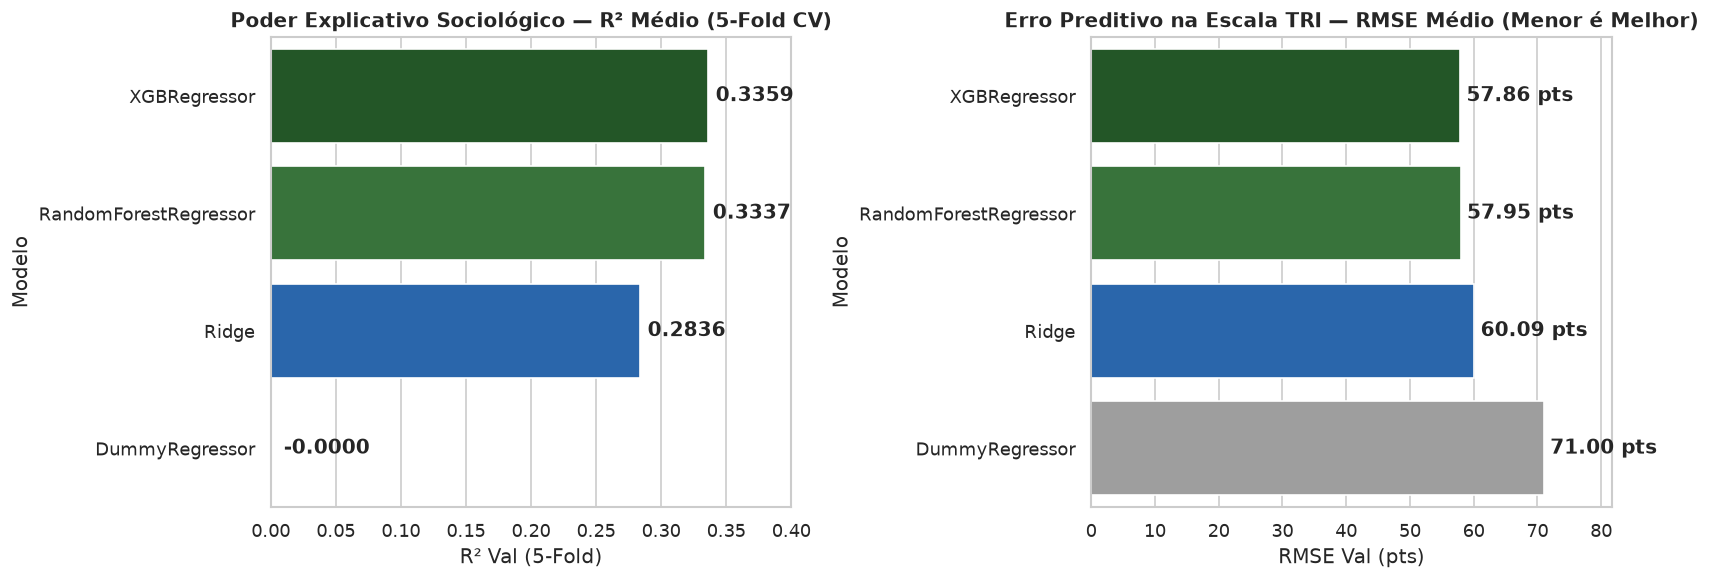

In [4]:
# ==============================================================================
# SEÇÃO 4: ESTÁGIO 1 — BENCHMARK 5-FOLD CV CONCORRENTE RASTREADO NO MLFLOW
# ==============================================================================
X_cv = df_cv[FEATURES_ELITE]
y_cv = df_cv[ALVO_OFICIAL].to_numpy(dtype=np.float32)
anos_estrat_cv = df_cv[COLUNA_PARTICAO_TEMPORAL].to_numpy()
sigma_y_cv = float(np.std(y_cv))

# ── Bloco 4.1: Protocolo único de 5-Fold CV estratificado por ano da prova ────
skf_5fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# ── Bloco 4.2: Declaração dos 4 modelos sob competição controlada ─────────────
candidatos_cv = [
    (
        "estagio1_cv_01_dummy_media",
        "Baseline_Nulo",
        DummyRegressor(strategy="mean"),
    ),
    (
        "estagio1_cv_02_ridge_linear",
        "Linear_Parametrico",
        Ridge(alpha=1.0),
    ),
    (
        "estagio1_cv_03_random_forest",
        "Bagging_RandomForest",
        RandomForestRegressor(
            n_estimators=120,
            max_depth=12,
            min_samples_leaf=25,
            max_features="sqrt",
            n_jobs=N_THREADS_FISICAS,
            random_state=SEED,
        ),
    ),
    (
        "estagio1_cv_04_xgboost_hist",
        "Boosting_XGBoost",
        XGBRegressor(
            tree_method="hist",
            max_bin=256,
            n_estimators=300,
            learning_rate=0.08,
            max_depth=6,
            min_child_weight=25,
            subsample=0.80,
            colsample_bytree=0.80,
            reg_lambda=1.0,
            n_jobs=N_THREADS_LOGICAS,
            random_state=SEED,
        ),
    ),
]

# ── Bloco 4.3: Avaliação nos mesmos 5 folds e registro no MLflow ──────────────
scoring_cv = {
    "r2": "r2",
    "neg_rmse": "neg_root_mean_squared_error",
    "neg_mae": "neg_mean_absolute_error",
}

resultados_estagio1 = []
print("=" * 96)
print(f"INICIANDO ESTÁGIO 1: BATALHA 5-FOLD CV ESTRATIFICADA (N = {len(X_cv):,} CANDIDATOS)")
print("=" * 96)

for run_name, familia, estimador in candidatos_cv:
    t0_m = time.perf_counter()
    with mlflow.start_run(run_name=run_name) as run_ativa:
        mlflow.set_tags({
            "estagio": "1_benchmark_5fold_cv",
            "familia_modelo": familia,
            "classe_estimador": estimador.__class__.__name__,
            "escopo_dados": f"amostra_estratificada_{len(X_cv)}",
        })

        # Registra apenas parâmetros escalares relevantes do estimador
        params_limpos = {
            k: v for k, v in estimador.get_params().items()
            if isinstance(v, (int, float, str, bool)) or v is None
        }
        mlflow.log_params(params_limpos)
        mlflow.log_param("cv_n_splits", 5)
        mlflow.log_param("n_amostras_cv", len(X_cv))

        # n_jobs=1 no loop externo evita cópia da matriz X_cv em múltiplos processos Python;
        # o paralelismo multi-core ocorre dentro do próprio estimador (RF / XGBoost).
        cv_out = cross_validate(
            estimator=estimador,
            X=X_cv,
            y=y_cv,
            cv=skf_5fold.split(X_cv, anos_estrat_cv),
            scoring=scoring_cv,
            n_jobs=1,
            return_train_score=True,
        )
        duracao_cv = round(time.perf_counter() - t0_m, 2)

        r2_val_mean = float(np.mean(cv_out["test_r2"]))
        r2_val_std = float(np.std(cv_out["test_r2"]))
        r2_train_mean = float(np.mean(cv_out["train_r2"]))
        rmse_val_mean = float(-np.mean(cv_out["test_neg_rmse"]))
        rmse_val_std = float(np.std(-cv_out["test_neg_rmse"]))
        mae_val_mean = float(-np.mean(cv_out["test_neg_mae"]))
        erro_rel_cv = rmse_val_mean / sigma_y_cv

        metricas_mlflow = {
            "cv_r2_mean": round(r2_val_mean, 5),
            "cv_r2_std": round(r2_val_std, 5),
            "cv_r2_train_mean": round(r2_train_mean, 5),
            "cv_gap_generalizacao_r2": round(r2_train_mean - r2_val_mean, 5),
            "cv_rmse_mean": round(rmse_val_mean, 4),
            "cv_rmse_std": round(rmse_val_std, 4),
            "cv_mae_mean": round(mae_val_mean, 4),
            "cv_erro_relativo_sigma": round(erro_rel_cv, 5),
            "tempo_execucao_s": duracao_cv,
        }
        mlflow.log_metrics(metricas_mlflow)

        resultados_estagio1.append({
            "Modelo": estimador.__class__.__name__,
            "Família": familia,
            "R² Val (5-Fold)": round(r2_val_mean, 4),
            "± DP R²": round(r2_val_std, 4),
            "R² Treino": round(r2_train_mean, 4),
            "RMSE Val (pts)": round(rmse_val_mean, 2),
            "MAE Val (pts)": round(mae_val_mean, 2),
            "RMSE / σ": round(erro_rel_cv, 4),
            "Tempo (s)": duracao_cv,
            "MLflow Run ID": run_ativa.info.run_id[:8],
        })

        print(
            f"✅ {estimador.__class__.__name__:<23} | R²={r2_val_mean:.4f} (±{r2_val_std:.4f}) | "
            f"RMSE={rmse_val_mean:6.2f} pts | MAE={mae_val_mean:6.2f} pts | "
            f"RMSE/σ={erro_rel_cv:.4f} | {duracao_cv:5.1f}s"
        )
    gc.collect()

df_benchmark_cv = (
    pd.DataFrame(resultados_estagio1)
    .sort_values("RMSE Val (pts)", ascending=True)
    .reset_index(drop=True)
)
display(df_benchmark_cv)

# ── Bloco 4.4: Gráfico comparativo do Benchmark 5-Fold CV ─────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cores_modelos = ["#1b5e20", "#2e7d32", "#1565c0", "#9e9e9e"]

sns.barplot(
    data=df_benchmark_cv,
    x="R² Val (5-Fold)",
    y="Modelo",
    hue="Modelo",
    palette=cores_modelos,
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Poder Explicativo Sociológico — R² Médio (5-Fold CV)")
axes[0].set_xlim(0, max(0.40, df_benchmark_cv["R² Val (5-Fold)"].max() * 1.15))
for idx_b, row_b in df_benchmark_cv.iterrows():
    axes[0].text(
        max(row_b["R² Val (5-Fold)"] + 0.006, 0.01),
        idx_b,
        f"{row_b['R² Val (5-Fold)']:.4f}",
        va="center",
        fontweight="bold",
    )

sns.barplot(
    data=df_benchmark_cv,
    x="RMSE Val (pts)",
    y="Modelo",
    hue="Modelo",
    palette=cores_modelos,
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Erro Preditivo na Escala TRI — RMSE Médio (Menor é Melhor)")
axes[1].set_xlim(0, df_benchmark_cv["RMSE Val (pts)"].max() * 1.15)
for idx_b, row_b in df_benchmark_cv.iterrows():
    axes[1].text(
        row_b["RMSE Val (pts)"] + 1.0,
        idx_b,
        f"{row_b['RMSE Val (pts)']:.2f} pts",
        va="center",
        fontweight="bold",
    )

plt.tight_layout()
caminho_fig_bench = FIGURES_DIR / "01_benchmark_5fold_cv.png"
fig.savefig(caminho_fig_bench, bbox_inches="tight")
plt.show()

---
## 5. Otimização Concorrente de Hiperparâmetros (*Tuning*) e Curva de Aprendizado (Estágio 2)

### O que esta célula faz?
Antes de escalar para dezenas de milhões de registros, refinamos os hiperparâmetros das duas famílias de árvores e demonstramos matematicamente como o erro reage ao aumento de volume de dados:

* **Bloco 5.1 (Grade Estruturada Concorrente — *Random Forest* e *XGBoost*):** Avalia sob Validação Cruzada Estratificada (`3-Fold CV` sobre `df_cv`) configurações contrastantes de profundidade (`max_depth`), regularização de folhas (`min_samples_leaf` / `min_child_weight`), taxa de aprendizado (`learning_rate`), penalização $L_2$ (`reg_lambda`) e amostragem de colunas (`max_features` / `colsample_bytree`).
* **Bloco 5.2 (*Nested Runs* no MLflow):** Registra cada combinação testada como uma *Child Run* aninhada no MLflow (permitindo gerar o *Parallel Coordinates Plot* nativo na interface do MLflow) e seleciona automaticamente `melhores_params_rf` e `melhores_params_xgb`.
* **Bloco 5.3 (Estágio 2 — Curva de Aprendizado Escalável no MLflow):** Treina o XGBoost otimizado em fatias estratificadas crescentes de `df_fit` (`50k` $\rightarrow$ `200k` $\rightarrow$ `1M` $\rightarrow$ `5M` $\rightarrow$ `15M` de alunos), avaliando sempre nos `3.007.490` alunos fixos de `df_val_es` e registrando `02_curva_aprendizado_escalavel.png`.

INICIANDO TUNING CONCORRENTE COM NESTED RUNS NO MLFLOW (3-FOLD CV ESTRATIFICADO)
   [RF-01]  R²=0.33295 | RMSE=57.9852 pts | 116.5s
   [RF-02]  R²=0.33356 | RMSE=57.9589 pts | 161.9s
   [RF-03]  R²=0.33219 | RMSE=58.0185 pts | 219.3s
   [RF-04]  R²=0.33188 | RMSE=58.0316 pts | 265.0s
   [RF-05]  R²=0.33146 | RMSE=58.0500 pts | 224.6s
   [XGB-01] R²=0.33578 | RMSE=57.8619 pts |  62.8s
   [XGB-02] R²=0.33547 | RMSE=57.8757 pts |  65.2s
   [XGB-03] R²=0.33510 | RMSE=57.8919 pts |  77.5s
   [XGB-04] R²=0.33441 | RMSE=57.9216 pts | 104.1s
   [XGB-05] R²=0.33463 | RMSE=57.9123 pts | 107.2s
   [XGB-06] R²=0.33516 | RMSE=57.8891 pts |  99.9s

🏆 Melhores Hiperparâmetros Random Forest : {'n_estimators': 150, 'max_depth': 12, 'min_samples_leaf': 20, 'max_features': 'sqrt'}
🏆 Melhores Hiperparâmetros XGBoost       : {'n_estimators': 300, 'learning_rate': 0.1, 'max_depth': 5, 'min_child_weight': 30, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 1.0}


,Família,Trial,Resumo Config,R² CV,RMSE CV,Tempo (s)
0,XGBoost,XGB-01,"trees=300, lr=0.1, depth=5, mcw=30, l2=1.0",0.33578,57.8619,62.77
1,XGBoost,XGB-02,"trees=350, lr=0.08, depth=6, mcw=25, l2=1.5",0.33547,57.8757,65.25
2,XGBoost,XGB-06,"trees=500, lr=0.04, depth=7, mcw=35, l2=2.5",0.33516,57.8891,99.93
3,XGBoost,XGB-03,"trees=400, lr=0.06, depth=7, mcw=30, l2=2.0",0.33510,57.8919,77.53
4,XGBoost,XGB-05,"trees=400, lr=0.05, depth=9, mcw=60, l2=5.0",0.33463,57.9123,107.18
5,XGBoost,XGB-04,"trees=450, lr=0.05, depth=8, mcw=40, l2=3.0",0.33441,57.9216,104.12
6,RandomForest,RF-02,"trees=150, depth=12, leaf=20, feat=sqrt",0.33356,57.9589,161.91
7,RandomForest,RF-01,"trees=120, depth=10, leaf=30, feat=sqrt",0.33295,57.9852,116.49
8,RandomForest,RF-03,"trees=150, depth=14, leaf=20, feat=0.5",0.33219,58.0185,219.31
9,RandomForest,RF-04,"trees=180, depth=14, leaf=15, feat=0.5",0.33188,58.0316,264.98



INICIANDO ESTÁGIO 2: CURVA DE APRENDIZADO ESCALÁVEL (50 MIL -> 15 MILHÕES DE ALUNOS)
📈 Volume=    50,000 | RMSE Treino=57.086 | RMSE Validação=58.059 | R² Val=0.32967 |  14.4s
📈 Volume=   200,000 | RMSE Treino=57.397 | RMSE Validação=57.825 | R² Val=0.33507 |  15.2s
📈 Volume= 1,000,000 | RMSE Treino=57.700 | RMSE Validação=57.755 | R² Val=0.33669 |  34.0s
📈 Volume= 5,000,000 | RMSE Treino=57.754 | RMSE Validação=57.738 | R² Val=0.33708 | 117.0s
📈 Volume=15,000,000 | RMSE Treino=57.762 | RMSE Validação=57.734 | R² Val=0.33716 | 333.3s


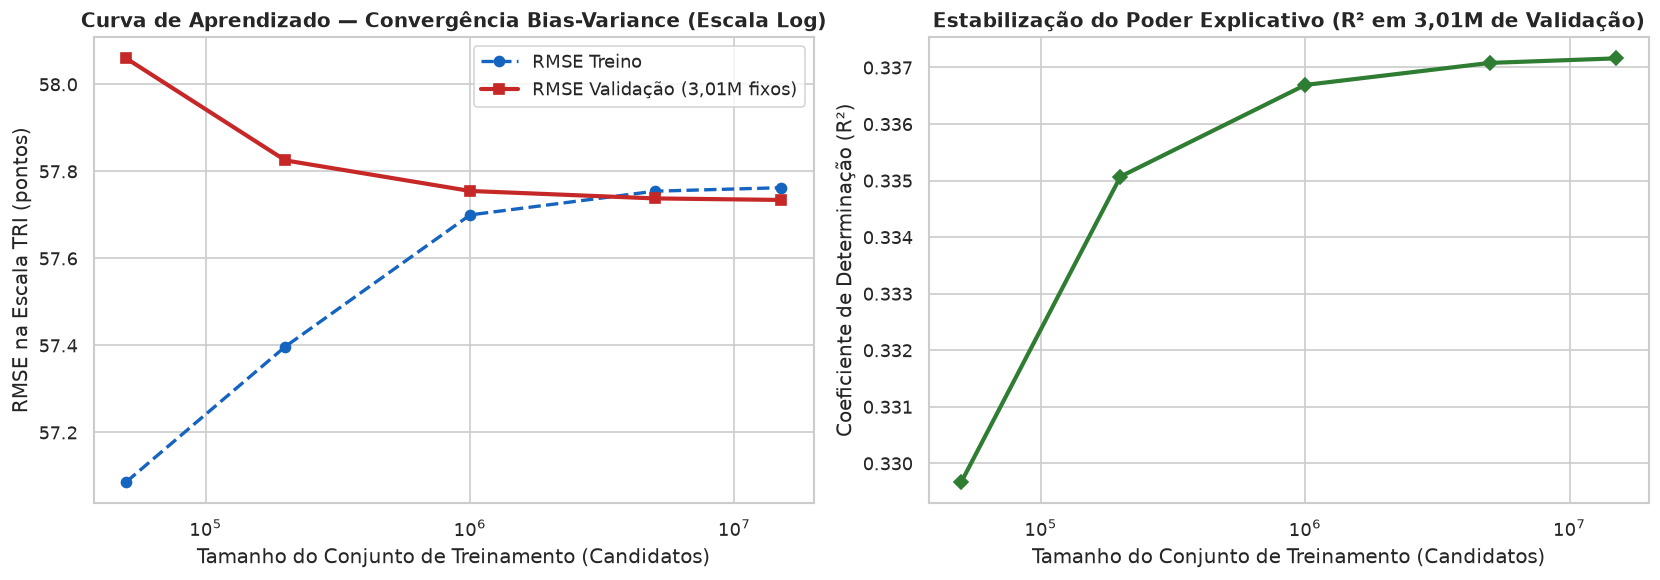

,n_amostras_treino,rotulo_escala,rmse_treino,rmse_validacao,r2_validacao,tempo_treino_s
0,50000,50k,57.0861,58.0594,0.32967,14.40
1,200000,200k,57.3972,57.8250,0.33507,15.25
2,1000000,1.00M,57.6997,57.7547,0.33669,34.03
3,5000000,5.00M,57.7542,57.7376,0.33708,117.05
4,15000000,15.00M,57.7622,57.7341,0.33716,333.27


In [5]:
# ==============================================================================
# SEÇÃO 5: TUNING CONCORRENTE (NESTED RUNS MLFLOW) E CURVA DE APRENDIZADO
# ==============================================================================
skf_tuning = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

# ── Bloco 5.1: Espaços de busca defensáveis para Random Forest e XGBoost ──────
grade_rf = [
    {"n_estimators": 120, "max_depth": 10, "min_samples_leaf": 30, "max_features": "sqrt"},
    {"n_estimators": 150, "max_depth": 12, "min_samples_leaf": 20, "max_features": "sqrt"},
    {"n_estimators": 150, "max_depth": 14, "min_samples_leaf": 20, "max_features": 0.50},
    {"n_estimators": 180, "max_depth": 14, "min_samples_leaf": 15, "max_features": 0.50},
    {"n_estimators": 150, "max_depth": 16, "min_samples_leaf": 25, "max_features": 0.50},
]

grade_xgb = [
    {"n_estimators": 300, "learning_rate": 0.10, "max_depth": 5, "min_child_weight": 30, "subsample": 0.80, "colsample_bytree": 0.80, "reg_lambda": 1.0},
    {"n_estimators": 350, "learning_rate": 0.08, "max_depth": 6, "min_child_weight": 25, "subsample": 0.80, "colsample_bytree": 0.85, "reg_lambda": 1.5},
    {"n_estimators": 400, "learning_rate": 0.06, "max_depth": 7, "min_child_weight": 30, "subsample": 0.85, "colsample_bytree": 0.85, "reg_lambda": 2.0},
    {"n_estimators": 450, "learning_rate": 0.05, "max_depth": 8, "min_child_weight": 40, "subsample": 0.85, "colsample_bytree": 0.85, "reg_lambda": 3.0},
    {"n_estimators": 400, "learning_rate": 0.05, "max_depth": 9, "min_child_weight": 60, "subsample": 0.80, "colsample_bytree": 0.80, "reg_lambda": 5.0},
    {"n_estimators": 500, "learning_rate": 0.04, "max_depth": 7, "min_child_weight": 35, "subsample": 0.85, "colsample_bytree": 1.00, "reg_lambda": 2.5},
]

# ── Bloco 5.2: Execução do Tuning com Nested Runs auditáveis no MLflow ────────
historico_tuning = []
melhor_rmse_rf = float("inf")
melhores_params_rf = None

melhor_rmse_xgb = float("inf")
melhores_params_xgb = None

print("=" * 96)
print("INICIANDO TUNING CONCORRENTE COM NESTED RUNS NO MLFLOW (3-FOLD CV ESTRATIFICADO)")
print("=" * 96)

with mlflow.start_run(run_name="estagio1_tuning_parent_rf_vs_xgb"):
    mlflow.set_tag("estagio", "1b_hyperparameter_tuning_parent")

    # 1) Tuning Random Forest (Bagging)
    for idx_cfg, cfg_rf in enumerate(grade_rf, start=1):
        t0_c = time.perf_counter()
        with mlflow.start_run(run_name=f"trial_rf_{idx_cfg:02d}", nested=True):
            mlflow.set_tags({"familia_modelo": "Bagging_RandomForest", "estagio": "1b_tuning_trial"})
            mlflow.log_params(cfg_rf)

            est_rf = RandomForestRegressor(
                **cfg_rf,
                n_jobs=N_THREADS_FISICAS,
                random_state=SEED,
            )
            cv_res = cross_validate(
                est_rf,
                X_cv,
                y_cv,
                cv=skf_tuning.split(X_cv, anos_estrat_cv),
                scoring={"r2": "r2", "neg_rmse": "neg_root_mean_squared_error"},
                n_jobs=1,
            )
            rmse_m = float(-np.mean(cv_res["test_neg_rmse"]))
            r2_m = float(np.mean(cv_res["test_r2"]))
            dur_s = round(time.perf_counter() - t0_c, 2)

            mlflow.log_metrics({"cv_rmse_mean": round(rmse_m, 4), "cv_r2_mean": round(r2_m, 5), "tempo_s": dur_s})
            historico_tuning.append({
                "Família": "RandomForest",
                "Trial": f"RF-{idx_cfg:02d}",
                "Resumo Config": f"trees={cfg_rf['n_estimators']}, depth={cfg_rf['max_depth']}, leaf={cfg_rf['min_samples_leaf']}, feat={cfg_rf['max_features']}",
                "R² CV": round(r2_m, 5),
                "RMSE CV": round(rmse_m, 4),
                "Tempo (s)": dur_s,
            })
            if rmse_m < melhor_rmse_rf:
                melhor_rmse_rf = rmse_m
                melhores_params_rf = dict(cfg_rf)
            print(f"   [RF-{idx_cfg:02d}]  R²={r2_m:.5f} | RMSE={rmse_m:.4f} pts | {dur_s:5.1f}s")
        gc.collect()

    # 2) Tuning XGBoost (Histogram Gradient Boosting)
    for idx_cfg, cfg_xgb in enumerate(grade_xgb, start=1):
        t0_c = time.perf_counter()
        with mlflow.start_run(run_name=f"trial_xgb_{idx_cfg:02d}", nested=True):
            mlflow.set_tags({"familia_modelo": "Boosting_XGBoost", "estagio": "1b_tuning_trial"})
            mlflow.log_params(cfg_xgb)

            est_xgb = XGBRegressor(
                tree_method="hist",
                max_bin=256,
                **cfg_xgb,
                n_jobs=N_THREADS_LOGICAS,
                random_state=SEED,
            )
            cv_res = cross_validate(
                est_xgb,
                X_cv,
                y_cv,
                cv=skf_tuning.split(X_cv, anos_estrat_cv),
                scoring={"r2": "r2", "neg_rmse": "neg_root_mean_squared_error"},
                n_jobs=1,
            )
            rmse_m = float(-np.mean(cv_res["test_neg_rmse"]))
            r2_m = float(np.mean(cv_res["test_r2"]))
            dur_s = round(time.perf_counter() - t0_c, 2)

            mlflow.log_metrics({"cv_rmse_mean": round(rmse_m, 4), "cv_r2_mean": round(r2_m, 5), "tempo_s": dur_s})
            historico_tuning.append({
                "Família": "XGBoost",
                "Trial": f"XGB-{idx_cfg:02d}",
                "Resumo Config": (
                    f"trees={cfg_xgb['n_estimators']}, lr={cfg_xgb['learning_rate']}, "
                    f"depth={cfg_xgb['max_depth']}, mcw={cfg_xgb['min_child_weight']}, l2={cfg_xgb['reg_lambda']}"
                ),
                "R² CV": round(r2_m, 5),
                "RMSE CV": round(rmse_m, 4),
                "Tempo (s)": dur_s,
            })
            if rmse_m < melhor_rmse_xgb:
                melhor_rmse_xgb = rmse_m
                melhores_params_xgb = dict(cfg_xgb)
            print(f"   [XGB-{idx_cfg:02d}] R²={r2_m:.5f} | RMSE={rmse_m:.4f} pts | {dur_s:5.1f}s")
        gc.collect()

    mlflow.log_metrics({
        "melhor_rf_cv_rmse": round(melhor_rmse_rf, 4),
        "melhor_xgb_cv_rmse": round(melhor_rmse_xgb, 4),
    })

df_tuning = pd.DataFrame(historico_tuning).sort_values("RMSE CV", ascending=True).reset_index(drop=True)
print("\n🏆 Melhores Hiperparâmetros Random Forest :", melhores_params_rf)
print("🏆 Melhores Hiperparâmetros XGBoost       :", melhores_params_xgb)
display(df_tuning)

# Libera df_cv pois os estágios seguintes operam diretamente sobre df_fit e df_val_es
del X_cv, y_cv, anos_estrat_cv, df_cv
gc.collect()

# ── Bloco 5.3: Estágio 2 — Curva de Aprendizado Escalável no MLflow ───────────
degraus_volume = [50_000, 200_000, 1_000_000, 5_000_000, 15_000_000]
y_val_es_np = df_val_es[ALVO_OFICIAL].to_numpy(dtype=np.float32)

# Permutação única de índices de df_fit para subamostras aninhadas consistentes
ordem_fit = rng.permutation(len(df_fit))
registros_curva = []

print("\n" + "=" * 96)
print("INICIANDO ESTÁGIO 2: CURVA DE APRENDIZADO ESCALÁVEL (50 MIL -> 15 MILHÕES DE ALUNOS)")
print("=" * 96)

with mlflow.start_run(run_name="estagio2_curva_aprendizado_escalavel"):
    mlflow.set_tags({"estagio": "2_curva_aprendizado", "familia_modelo": "Boosting_XGBoost"})
    mlflow.log_params(melhores_params_xgb)

    for n_amostras in degraus_volume:
        t0_deg = time.perf_counter()
        fatia_idx = ordem_fit[:n_amostras]
        df_sub = df_fit.iloc[fatia_idx]

        modelo_curva = XGBRegressor(
            tree_method="hist",
            max_bin=256,
            **melhores_params_xgb,
            n_jobs=N_THREADS_LOGICAS,
            random_state=SEED,
        )
        modelo_curva.fit(df_sub[FEATURES_ELITE], df_sub[ALVO_OFICIAL], verbose=False)

        pred_sub_train = prever_em_blocos(modelo_curva, df_sub, FEATURES_ELITE)
        pred_val_es = prever_em_blocos(modelo_curva, df_val_es, FEATURES_ELITE)

        met_tr = calcular_metricas_regressao(df_sub[ALVO_OFICIAL].to_numpy(dtype=np.float32), pred_sub_train)
        met_va = calcular_metricas_regressao(y_val_es_np, pred_val_es)
        tempo_deg = round(time.perf_counter() - t0_deg, 2)

        mlflow.log_metric("lc_train_rmse", met_tr["rmse"], step=n_amostras)
        mlflow.log_metric("lc_val_rmse", met_va["rmse"], step=n_amostras)
        mlflow.log_metric("lc_val_r2", met_va["r2"], step=n_amostras)

        registros_curva.append({
            "n_amostras_treino": n_amostras,
            "rotulo_escala": f"{n_amostras / 1e6:.2f}M" if n_amostras >= 1_000_000 else f"{n_amostras // 1000}k",
            "rmse_treino": met_tr["rmse"],
            "rmse_validacao": met_va["rmse"],
            "r2_validacao": met_va["r2"],
            "tempo_treino_s": tempo_deg,
        })
        print(
            f"📈 Volume={n_amostras:>10,} | RMSE Treino={met_tr['rmse']:.3f} | "
            f"RMSE Validação={met_va['rmse']:.3f} | R² Val={met_va['r2']:.5f} | {tempo_deg:5.1f}s"
        )

        del df_sub, modelo_curva, pred_sub_train, pred_val_es
        gc.collect()

    df_curva_aprendizado = pd.DataFrame(registros_curva)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(
        df_curva_aprendizado["n_amostras_treino"],
        df_curva_aprendizado["rmse_treino"],
        marker="o",
        linewidth=2,
        linestyle="--",
        color="#1565c0",
        label="RMSE Treino",
    )
    axes[0].plot(
        df_curva_aprendizado["n_amostras_treino"],
        df_curva_aprendizado["rmse_validacao"],
        marker="s",
        linewidth=2.5,
        color="#c62828",
        label="RMSE Validação (3,01M fixos)",
    )
    axes[0].set_xscale("log")
    axes[0].set_title("Curva de Aprendizado — Convergência Bias-Variance (Escala Log)")
    axes[0].set_xlabel("Tamanho do Conjunto de Treinamento (Candidatos)")
    axes[0].set_ylabel("RMSE na Escala TRI (pontos)")
    axes[0].legend()

    axes[1].plot(
        df_curva_aprendizado["n_amostras_treino"],
        df_curva_aprendizado["r2_validacao"],
        marker="D",
        linewidth=2.5,
        color="#2e7d32",
    )
    axes[1].set_xscale("log")
    axes[1].set_title("Estabilização do Poder Explicativo (R² em 3,01M de Validação)")
    axes[1].set_xlabel("Tamanho do Conjunto de Treinamento (Candidatos)")
    axes[1].set_ylabel("Coeficiente de Determinação (R²)")

    plt.tight_layout()
    caminho_fig_lc = FIGURES_DIR / "02_curva_aprendizado_escalavel.png"
    fig.savefig(caminho_fig_lc, bbox_inches="tight")
    mlflow.log_artifact(str(caminho_fig_lc))
    plt.show()

del ordem_fit, y_val_es_np
gc.collect()
display(df_curva_aprendizado)

---
## 6. Estágio 3 — Treinamento Final em Escala Censitária, Auditoria Anual e Validação *Out-of-Time* Interna

### O que esta célula faz?
Chegamos ao momento decisivo do treinamento e da validação cega em **3 blocos rigorosos**:

* **Bloco 6.1 (Disputa Final no Holdout Cego de `7.518.726` Candidatos):**
  * **Random Forest Otimizado (Escala Máxima Segura em CPU/RAM):** No `scikit-learn`, cada árvore de *Bagging* com cortes exatos aloca vetores de pesos `int64` (`np.bincount`) proporcionais a $N$. Como a Curva de Aprendizado da Seção 5 provou estabilização assintótica acima de `1M–3M` de registros nas 6 variáveis discretas, treinamos o `RandomForestRegressor` otimizado sobre **`3.000.000` de alunos estratificados** (`< 300 MB` de RAM adicional) e avaliamos nos **`7.518.726` alunos cegos de `df_test`**.
  * **XGBoost `hist` Censo Integral (`30.074.903` Alunos = 100% do Desenvolvimento):** Graças à quantização em histogramas de `1 byte` (`max_bin=256`), ajustamos o `XGBRegressor` sobre os **`27.067.413` registros integrais de `df_fit`** com *Early Stopping* (`early_stopping_rounds=25`) monitorado nos **`3.007.490` registros de `df_val_es`**, avaliando em seguida nos mesmos **`7.518.726` alunos lacrados de `df_test`**.
  * O algoritmo com menor $\text{RMSE}$ no Holdout é coroado formalmente como **`modelo_campeao`**.
* **Bloco 6.2 (Auditoria Desagregada Ano a Ano `2014–2023`):** Mede $R^2$, $\text{RMSE}$, $\text{MAE}$ e Viés Médio ($\overline{\hat{y}} - \overline{y}$) em cada uma das 10 edições separadamente dentro do conjunto de teste cego (`03_estabilidade_anual_holdout.png`).
* **Bloco 6.3 (Rodada Extra no MLflow — Validação *Out-of-Time* Interna `2014–2022 -> 2023`):** Treina um modelo estritamente com dados até `2022` (`NU_ANO <= 2022`, **zero** exemplos de 2023) e testa nos **`2.678.264` candidatos integrais do ENEM 2023**, comprovando generalização temporal genuína antes da chegada do ENEM 2024 na Etapa 3.

ESTÁGIO 3A: TREINAMENTO FINAL RANDOM FOREST OTIMIZADO vs. HOLDOUT CEGO (7,52M)
✅ Random Forest Final | R² Holdout=0.33606 | RMSE=57.8198 pts | MAE=45.6635 pts | Treino=335.7s

ESTÁGIO 3B: TREINAMENTO FINAL XGBOOST HIST NO CENSO INTEGRAL (27,067,413 FIT + 3,007,490 EARLY STOPPING)
[0]	validation_0-rmse:69.45645
[100]	validation_0-rmse:57.77271
[200]	validation_0-rmse:57.74466
[300]	validation_0-rmse:57.73410
[400]	validation_0-rmse:57.72795
[500]	validation_0-rmse:57.72404
[600]	validation_0-rmse:57.72140
[649]	validation_0-rmse:57.72048
✅ XGBoost Censo Final | Best Iter=649 | R² Holdout=0.33780 | RMSE=57.7439 pts | MAE=45.5904 pts | Treino=1224.1s

🏆 MODELO CAMPEÃO ELEITO PARA PRODUÇÃO (enem.pkl): XGBRegressor


,Candidato Final,"R² Holdout (7,52M)",RMSE Holdout (pts),MAE Holdout (pts),RMSE / σ,Latência / 10k (ms),Tempo Treino (s)
0,"XGBRegressor (Censo 27,07M + ES 3,01M)",0.33780,57.7439,45.5904,0.81376,81.151,1224.12
1,"RandomForestRegressor (3,000,000 Estrat.)",0.33606,57.8198,45.6635,0.81483,124.419,335.68


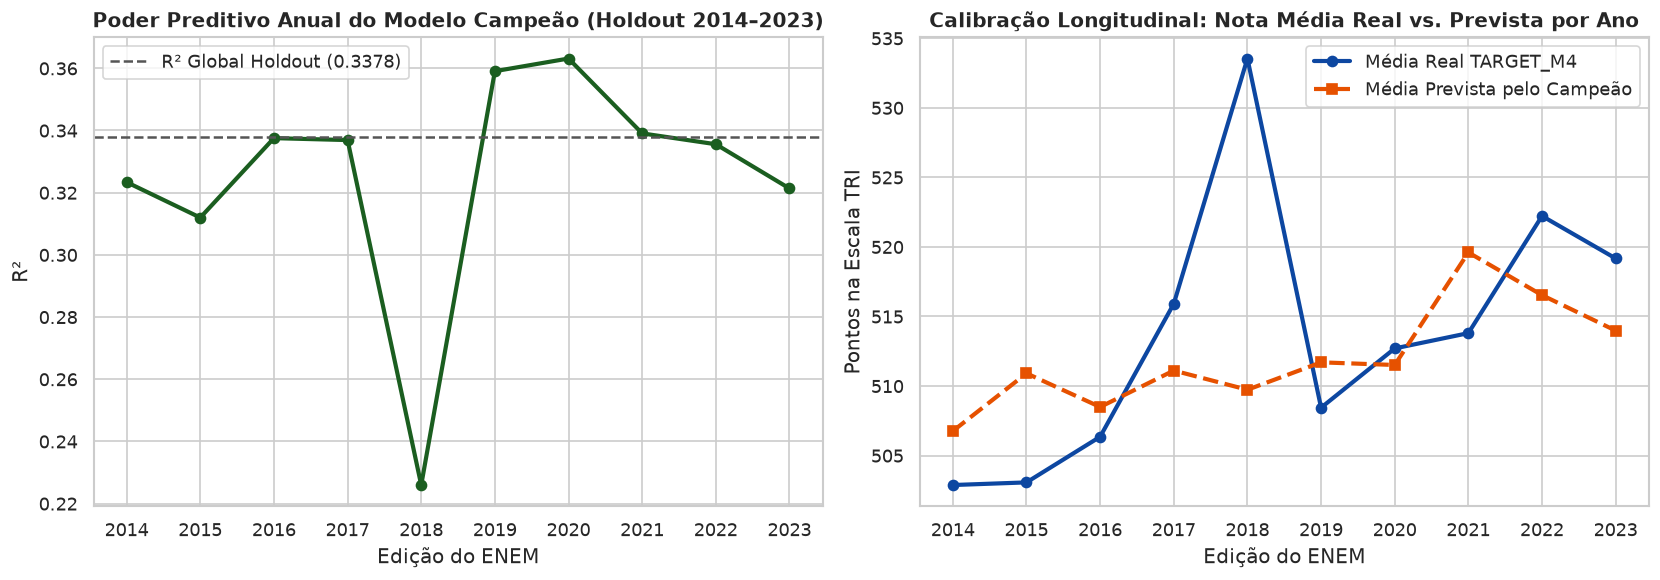

,ano,n_holdout,r2,rmse,mae,erro_relativo_sigma,media_real_m4,media_prevista_m4,vies_medio_pts
0,2014,1189582,0.32337,55.2154,43.6748,0.82258,502.88,506.76,3.88
1,2015,1120829,0.31197,55.3231,43.6841,0.82948,503.07,510.91,7.84
2,2016,1163652,0.33753,53.5267,42.0634,0.81392,506.35,508.49,2.14
3,2017,885338,0.33691,55.0361,43.6202,0.81430,515.91,511.11,-4.81
4,2018,454443,0.22595,60.4108,47.3885,0.87980,533.54,509.73,-23.81
5,2019,740382,0.35907,56.5617,45.3023,0.80058,508.44,511.70,3.26
6,2020,512261,0.36314,63.2968,50.8302,0.79804,512.70,511.51,-1.19
7,2021,447621,0.33906,63.9227,51.3477,0.81298,513.80,519.60,5.80
8,2022,468965,0.33557,59.3520,46.7935,0.81512,522.22,516.53,-5.69
9,2023,535653,0.32135,67.4472,52.7483,0.82380,519.17,513.98,-5.19



ESTÁGIO 3C: VALIDAÇÃO OUT-OF-TIME INTERNA (TREINO 2014–2022 -> TESTE CEGO INTEGRAL 2023)
✅ Validação Out-of-Time (2014–2022 -> 2023 Cego, N=2,678,264):
   • R² Futuro Cego = 0.31842 | RMSE = 67.6232 pts | MAE = 52.8526 pts | Viés Médio = -5.52 pts (1191.1s)


9787

In [6]:
# ==============================================================================
# SEÇÃO 6: ESTÁGIO 3 — TREINO FINAL CENSO, HOLDOUT (7,52M) E OOT INTERNA (2023)
# ==============================================================================
y_test_np = df_test[ALVO_OFICIAL].to_numpy(dtype=np.float32)

# ── Bloco 6.1A: Random Forest Otimizado em Escala Segura (3M Estratificados) ──
N_RF_CENSO = min(3_000_000, len(df_fit))
anos_fit_arr = df_fit[COLUNA_PARTICAO_TEMPORAL].to_numpy()
idx_rf_partes = []
acum_rf = 0
for i, ano in enumerate(ANOS_HOMOLOGADOS):
    idx_a = np.flatnonzero(anos_fit_arr == ano)
    if i < len(ANOS_HOMOLOGADOS) - 1:
        q_a = int(round(N_RF_CENSO * (len(idx_a) / len(df_fit))))
        acum_rf += q_a
    else:
        q_a = N_RF_CENSO - acum_rf
    idx_rf_partes.append(rng.choice(idx_a, size=q_a, replace=False))

idx_rf_final = rng.permutation(np.concatenate(idx_rf_partes))
df_fit_rf = df_fit.iloc[idx_rf_final]
del anos_fit_arr, idx_rf_partes, idx_rf_final

print("=" * 96)
print("ESTÁGIO 3A: TREINAMENTO FINAL RANDOM FOREST OTIMIZADO vs. HOLDOUT CEGO (7,52M)")
print("=" * 96)

t0_rf_final = time.perf_counter()
with mlflow.start_run(run_name="estagio3_final_random_forest") as run_rf_final:
    mlflow.set_tags({
        "estagio": "3_treino_final_holdout",
        "familia_modelo": "Bagging_RandomForest",
        "avaliado_em_holdout_7_5m": "true",
    })
    mlflow.log_params(melhores_params_rf)
    mlflow.log_param("n_registros_treino", len(df_fit_rf))
    mlflow.log_param("n_registros_holdout_teste", len(df_test))

    modelo_rf_final = RandomForestRegressor(
        **melhores_params_rf,
        n_jobs=N_THREADS_FISICAS,
        random_state=SEED,
    )
    modelo_rf_final.fit(df_fit_rf[FEATURES_ELITE], df_fit_rf[ALVO_OFICIAL])
    tempo_treino_rf = round(time.perf_counter() - t0_rf_final, 2)

    t0_inf_rf = time.perf_counter()
    pred_test_rf = prever_em_blocos(modelo_rf_final, df_test, FEATURES_ELITE)
    latencia_10k_rf_ms = round(((time.perf_counter() - t0_inf_rf) / len(df_test)) * 10_000 * 1000, 3)

    metricas_holdout_rf = calcular_metricas_regressao(y_test_np, pred_test_rf)
    mlflow.log_metrics({
        "holdout_r2": metricas_holdout_rf["r2"],
        "holdout_rmse": metricas_holdout_rf["rmse"],
        "holdout_mae": metricas_holdout_rf["mae"],
        "holdout_erro_relativo_sigma": metricas_holdout_rf["erro_relativo_sigma"],
        "tempo_treino_s": tempo_treino_rf,
        "latencia_10k_amostras_ms": latencia_10k_rf_ms,
    })
    rf_final_run_id = run_rf_final.info.run_id

del df_fit_rf
gc.collect()

print(
    f"✅ Random Forest Final | R² Holdout={metricas_holdout_rf['r2']:.5f} | "
    f"RMSE={metricas_holdout_rf['rmse']:.4f} pts | MAE={metricas_holdout_rf['mae']:.4f} pts | "
    f"Treino={tempo_treino_rf:.1f}s"
)

# ── Bloco 6.1B: XGBoost Otimizado no Censo Integral (27,07M Fit + 3,01M ES) ───
print("\n" + "=" * 96)
print(
    f"ESTÁGIO 3B: TREINAMENTO FINAL XGBOOST HIST NO CENSO INTEGRAL "
    f"({len(df_fit):,} FIT + {len(df_val_es):,} EARLY STOPPING)"
)
print("=" * 96)

params_xgb_censo = dict(melhores_params_xgb)
# Permite até 650 árvores no censo completo, protegido por Early Stopping estrito em df_val_es
params_xgb_censo["n_estimators"] = max(params_xgb_censo.get("n_estimators", 400), 650)

t0_xgb_final = time.perf_counter()
with mlflow.start_run(run_name="estagio3_final_xgboost_censo_completo") as run_xgb_final:
    mlflow.set_tags({
        "estagio": "3_treino_final_holdout",
        "familia_modelo": "Boosting_XGBoost",
        "avaliado_em_holdout_7_5m": "true",
    })
    mlflow.log_params(params_xgb_censo)
    mlflow.log_param("early_stopping_rounds", 25)
    mlflow.log_param("n_registros_fit", len(df_fit))
    mlflow.log_param("n_registros_val_es", len(df_val_es))
    mlflow.log_param("n_registros_holdout_teste", len(df_test))

    modelo_xgb_final = XGBRegressor(
        tree_method="hist",
        max_bin=256,
        eval_metric="rmse",
        early_stopping_rounds=25,
        **params_xgb_censo,
        n_jobs=N_THREADS_LOGICAS,
        random_state=SEED,
    )
    modelo_xgb_final.fit(
        df_fit[FEATURES_ELITE],
        df_fit[ALVO_OFICIAL],
        eval_set=[(df_val_es[FEATURES_ELITE], df_val_es[ALVO_OFICIAL])],
        verbose=100,
    )
    tempo_treino_xgb = round(time.perf_counter() - t0_xgb_final, 2)
    melhor_iter_xgb = int(modelo_xgb_final.best_iteration)

    # Registra a curva de convergência iterativa do Early Stopping no MLflow
    curva_es_rmse = modelo_xgb_final.evals_result()["validation_0"]["rmse"]
    for passo_boost, val_rmse_iter in enumerate(curva_es_rmse):
        if passo_boost % 10 == 0 or passo_boost == len(curva_es_rmse) - 1:
            mlflow.log_metric("es_val_rmse", round(float(val_rmse_iter), 4), step=passo_boost)

    t0_inf_xgb = time.perf_counter()
    pred_test_xgb = prever_em_blocos(modelo_xgb_final, df_test, FEATURES_ELITE)
    latencia_10k_xgb_ms = round(((time.perf_counter() - t0_inf_xgb) / len(df_test)) * 10_000 * 1000, 3)

    metricas_holdout_xgb = calcular_metricas_regressao(y_test_np, pred_test_xgb)
    mlflow.log_metrics({
        "best_iteration": melhor_iter_xgb,
        "holdout_r2": metricas_holdout_xgb["r2"],
        "holdout_rmse": metricas_holdout_xgb["rmse"],
        "holdout_mae": metricas_holdout_xgb["mae"],
        "holdout_erro_relativo_sigma": metricas_holdout_xgb["erro_relativo_sigma"],
        "tempo_treino_s": tempo_treino_xgb,
        "latencia_10k_amostras_ms": latencia_10k_xgb_ms,
    })
    xgb_final_run_id = run_xgb_final.info.run_id

print(
    f"✅ XGBoost Censo Final | Best Iter={melhor_iter_xgb} | R² Holdout={metricas_holdout_xgb['r2']:.5f} | "
    f"RMSE={metricas_holdout_xgb['rmse']:.4f} pts | MAE={metricas_holdout_xgb['mae']:.4f} pts | "
    f"Treino={tempo_treino_xgb:.1f}s"
)

# ── Seleção matemática objetiva do Modelo Campeão no Holdout de 7,52M ─────────
if metricas_holdout_xgb["rmse"] <= metricas_holdout_rf["rmse"]:
    nome_campeao = "XGBRegressor"
    modelo_campeao = modelo_xgb_final
    pred_test_campeao = pred_test_xgb
    metricas_campeao = metricas_holdout_xgb
    campeao_run_id = xgb_final_run_id
    del modelo_rf_final, pred_test_rf
else:
    nome_campeao = "RandomForestRegressor"
    modelo_campeao = modelo_rf_final
    pred_test_campeao = pred_test_rf
    metricas_campeao = metricas_holdout_rf
    campeao_run_id = rf_final_run_id
    del modelo_xgb_final, pred_test_xgb
gc.collect()

df_comparativo_holdout = pd.DataFrame([
    {
        "Candidato Final": "XGBRegressor (Censo 27,07M + ES 3,01M)",
        "R² Holdout (7,52M)": metricas_holdout_xgb["r2"],
        "RMSE Holdout (pts)": metricas_holdout_xgb["rmse"],
        "MAE Holdout (pts)": metricas_holdout_xgb["mae"],
        "RMSE / σ": metricas_holdout_xgb["erro_relativo_sigma"],
        "Latência / 10k (ms)": latencia_10k_xgb_ms,
        "Tempo Treino (s)": tempo_treino_xgb,
    },
    {
        "Candidato Final": f"RandomForestRegressor ({N_RF_CENSO:,} Estrat.)",
        "R² Holdout (7,52M)": metricas_holdout_rf["r2"],
        "RMSE Holdout (pts)": metricas_holdout_rf["rmse"],
        "MAE Holdout (pts)": metricas_holdout_rf["mae"],
        "RMSE / σ": metricas_holdout_rf["erro_relativo_sigma"],
        "Latência / 10k (ms)": latencia_10k_rf_ms,
        "Tempo Treino (s)": tempo_treino_rf,
    },
])
print(f"\n🏆 MODELO CAMPEÃO ELEITO PARA PRODUÇÃO (enem.pkl): {nome_campeao}")
display(df_comparativo_holdout)

# ── Bloco 6.2: Auditoria desagregada por edição (2014 a 2023) no Holdout ──────
anos_test_np = df_test[COLUNA_PARTICAO_TEMPORAL].to_numpy()
metricas_anuais_lista = []

for ano in ANOS_HOMOLOGADOS:
    mask_a = anos_test_np == ano
    y_a = y_test_np[mask_a]
    p_a = pred_test_campeao[mask_a]
    m_a = calcular_metricas_regressao(y_a, p_a)
    metricas_anuais_lista.append({
        "ano": int(ano),
        "n_holdout": int(mask_a.sum()),
        "r2": m_a["r2"],
        "rmse": m_a["rmse"],
        "mae": m_a["mae"],
        "erro_relativo_sigma": m_a["erro_relativo_sigma"],
        "media_real_m4": round(float(np.mean(y_a)), 2),
        "media_prevista_m4": round(float(np.mean(p_a)), 2),
        "vies_medio_pts": round(float(np.mean(p_a - y_a)), 2),
    })

df_metricas_por_ano = pd.DataFrame(metricas_anuais_lista)
caminho_csv_anual = MODELS_DIR / "auditoria_holdout_por_ano_2014_2023.csv"
df_metricas_por_ano.to_csv(caminho_csv_anual, index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(df_metricas_por_ano["ano"], df_metricas_por_ano["r2"], marker="o", linewidth=2.5, color="#1b5e20")
axes[0].axhline(metricas_campeao["r2"], linestyle="--", color="#555555", label=f"R² Global Holdout ({metricas_campeao['r2']:.4f})")
axes[0].set_title("Poder Preditivo Anual do Modelo Campeão (Holdout 2014–2023)")
axes[0].set_xlabel("Edição do ENEM")
axes[0].set_ylabel("R²")
axes[0].set_xticks(ANOS_HOMOLOGADOS)
axes[0].legend()

axes[1].plot(df_metricas_por_ano["ano"], df_metricas_por_ano["media_real_m4"], marker="o", linewidth=2.5, color="#0d47a1", label="Média Real TARGET_M4")
axes[1].plot(df_metricas_por_ano["ano"], df_metricas_por_ano["media_prevista_m4"], marker="s", linewidth=2.5, linestyle="--", color="#e65100", label="Média Prevista pelo Campeão")
axes[1].set_title("Calibração Longitudinal: Nota Média Real vs. Prevista por Ano")
axes[1].set_xlabel("Edição do ENEM")
axes[1].set_ylabel("Pontos na Escala TRI")
axes[1].set_xticks(ANOS_HOMOLOGADOS)
axes[1].legend()

plt.tight_layout()
caminho_fig_anual = FIGURES_DIR / "03_estabilidade_anual_holdout.png"
fig.savefig(caminho_fig_anual, bbox_inches="tight")
plt.show()
display(df_metricas_por_ano)

# ── Bloco 6.3: Rodada Extra MLflow — Validação Out-of-Time Interna (2014–2022 -> 2023) ─
print("\n" + "=" * 96)
print("ESTÁGIO 3C: VALIDAÇÃO OUT-OF-TIME INTERNA (TREINO 2014–2022 -> TESTE CEGO INTEGRAL 2023)")
print("=" * 96)

t0_oot = time.perf_counter()
df_fit_oot = df_fit.loc[df_fit[COLUNA_PARTICAO_TEMPORAL] <= 2022]
df_val_oot = df_val_es.loc[df_val_es[COLUNA_PARTICAO_TEMPORAL] <= 2022]

# Carrega 100% da safra 2023 (2.678.264 alunos) sem qualquer intersecção com 2014–2022
caminho_2023_slim = CHECKPOINT_SAFRAS_DIR / "enem_2023_slim.parquet"
if caminho_2023_slim.exists():
    df_2023_cego = pd.read_parquet(caminho_2023_slim, engine="pyarrow")
else:
    df_2023_cego = pd.concat(
        [
            df_fit.loc[df_fit[COLUNA_PARTICAO_TEMPORAL] == 2023],
            df_val_es.loc[df_val_es[COLUNA_PARTICAO_TEMPORAL] == 2023],
            df_test.loc[df_test[COLUNA_PARTICAO_TEMPORAL] == 2023],
        ],
        ignore_index=True,
    )

with mlflow.start_run(run_name="estagio3_validacao_oot_interna_2014_2022_para_2023"):
    mlflow.set_tags({
        "estagio": "3c_out_of_time_interno",
        "janela_treino": "2014-2022",
        "janela_teste_futuro_cego": "2023",
        "familia_modelo": "Boosting_XGBoost",
    })
    mlflow.log_params(params_xgb_censo)
    mlflow.log_param("n_treino_2014_2022", len(df_fit_oot))
    mlflow.log_param("n_teste_cego_2023", len(df_2023_cego))

    modelo_oot_2023 = XGBRegressor(
        tree_method="hist",
        max_bin=256,
        eval_metric="rmse",
        early_stopping_rounds=25,
        **params_xgb_censo,
        n_jobs=N_THREADS_LOGICAS,
        random_state=SEED,
    )
    modelo_oot_2023.fit(
        df_fit_oot[FEATURES_ELITE],
        df_fit_oot[ALVO_OFICIAL],
        eval_set=[(df_val_oot[FEATURES_ELITE], df_val_oot[ALVO_OFICIAL])],
        verbose=False,
    )

    pred_oot_2023 = prever_em_blocos(modelo_oot_2023, df_2023_cego, FEATURES_ELITE)
    y_oot_2023 = df_2023_cego[ALVO_OFICIAL].to_numpy(dtype=np.float32)
    metricas_oot_2023 = calcular_metricas_regressao(y_oot_2023, pred_oot_2023)
    vies_oot_2023 = round(float(np.mean(pred_oot_2023 - y_oot_2023)), 3)
    tempo_oot = round(time.perf_counter() - t0_oot, 2)

    mlflow.log_metrics({
        "oot_2023_r2": metricas_oot_2023["r2"],
        "oot_2023_rmse": metricas_oot_2023["rmse"],
        "oot_2023_mae": metricas_oot_2023["mae"],
        "oot_2023_erro_relativo_sigma": metricas_oot_2023["erro_relativo_sigma"],
        "oot_2023_vies_medio_pts": vies_oot_2023,
        "tempo_execucao_s": tempo_oot,
    })

print(
    f"✅ Validação Out-of-Time (2014–2022 -> 2023 Cego, N={len(df_2023_cego):,}):\n"
    f"   • R² Futuro Cego = {metricas_oot_2023['r2']:.5f} | RMSE = {metricas_oot_2023['rmse']:.4f} pts | "
    f"MAE = {metricas_oot_2023['mae']:.4f} pts | Viés Médio = {vies_oot_2023:+.2f} pts ({tempo_oot:.1f}s)"
)

# Libera estruturas pesadas já cumpridas para deixar a RAM leve para o SHAP e Serialização
del df_fit_oot, df_val_oot, df_2023_cego, modelo_oot_2023, pred_oot_2023, y_oot_2023
del df_fit, df_val_es, anos_test_np
gc.collect()

---
## 7. Interpretabilidade Sociológica e Auditoria via Valores SHAP (*Explainable AI*)

### Por que o SHAP é peça central da defesa perante a banca?
Árvores impulsionadas (*Gradient Boosted Trees*) capturam interações não-lineares complexas, mas métricas agregadas não revelam **como** cada atributo desloca a nota de um estudante. Utilizando a Teoria dos Jogos Cooperativos de Lloyd Shapley (`TreeSHAP` exato em C++), decompomos cada predição individual $\hat{y}_i$ de forma estritamente aditiva:

$$\hat{y}_i = \underbrace{\phi_0}_{\mathbb{E}[f(X)] \approx 511\,\text{pts}} + \sum_{j=1}^{6} \phi_{ij}$$

onde $\phi_{ij}$ mede, **em pontos reais da escala TRI**, a contribuição marginal exata da feature $j$ para o estudante $i$:
* **Bloco 7.1 (Amostra Estratificada Cega e Cálculo Exato `TreeExplainer`):** Sorteia `10.000` candidatos do Holdout (`1.000` por edição de `2014` a `2023`) e calcula os valores SHAP exatos em poucos segundos.
* **Bloco 7.2 (Auditoria de Aditividade e Ranking em Pontos da TRI):** Verifica matematicamente que $|\phi_0 + \sum \phi_{ij} - \hat{y}_i| \approx 0$ e gera a tabela de impacto médio absoluto (`|SHAP| médio`).
* **Bloco 7.3 (Visão Global — Barras e *Beeswarm*):** Salva e exibe `04a_shap_importancia_barras.png` e `04b_shap_beeswarm.png`.
* **Bloco 7.4 (Interações de Bourdieu e Perfis Individuais Contrastantes):** Plota a concavidade da renda $\times$ computador e escolaridade materna $\times$ língua estrangeira (`05_shap_interacoes_bourdieu.png`), além de decompor lado a lado dois candidatos reais antagônicos do teste (`06_shap_perfis_contrastantes.png`).

AUDITORIA SHAP CONCLUÍDA EM 9.84s | VALOR BASE E[f(X)] = 511.04 PTS | ERRO ADITIVIDADE MÁX = 1.26e-03


,Feature,Descrição Sociológica,|SHAP| Médio (pts TRI),Participação Relativa (%),Min SHAP (pts),Max SHAP (pts)
0,RENDA_PER_CAPITA,Renda Per Capita (SM/morador),18.483,30.10,-41.93,85.96
1,TP_LINGUA,"Língua Estrangeira (0=Ing, 1=Esp)",10.895,17.74,-24.82,18.22
2,Q024,Posse de Computador (0 a 3+),9.487,15.45,-19.37,53.60
3,TP_ANO_CONCLUIU,Anos desde Conclusão EM (0 a 9+),8.958,14.59,-15.26,29.29
4,Q002,Escolaridade Materna (0 a 7),8.642,14.07,-42.82,27.64
5,TP_SEXO,"Sexo (0=Fem, 1=Masc)",4.946,8.05,-13.06,12.46


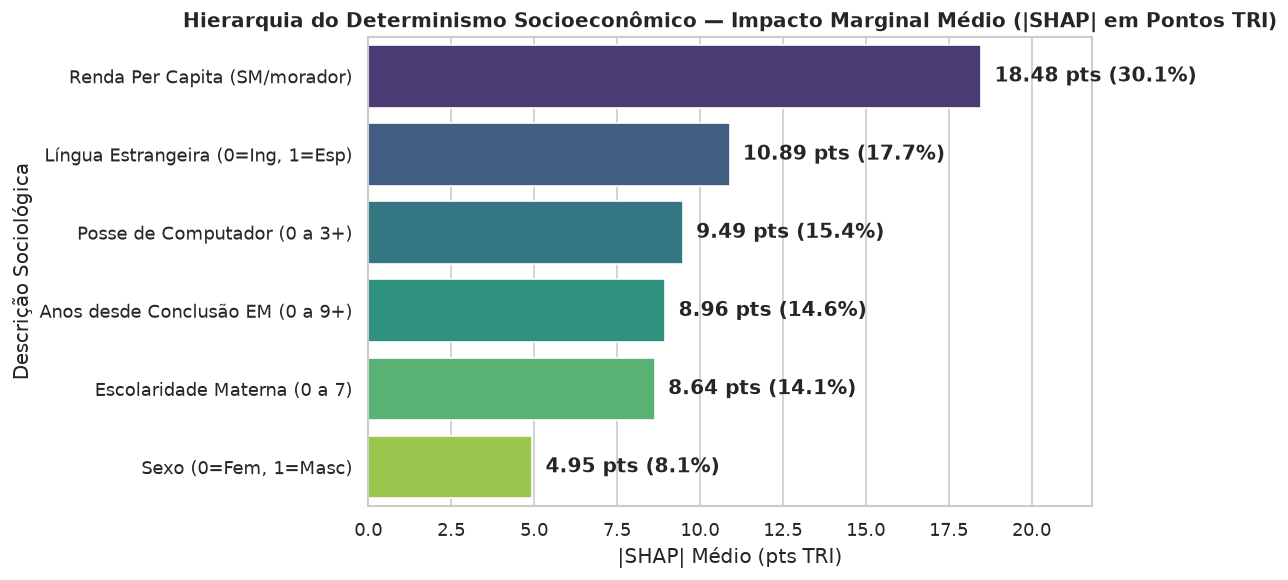

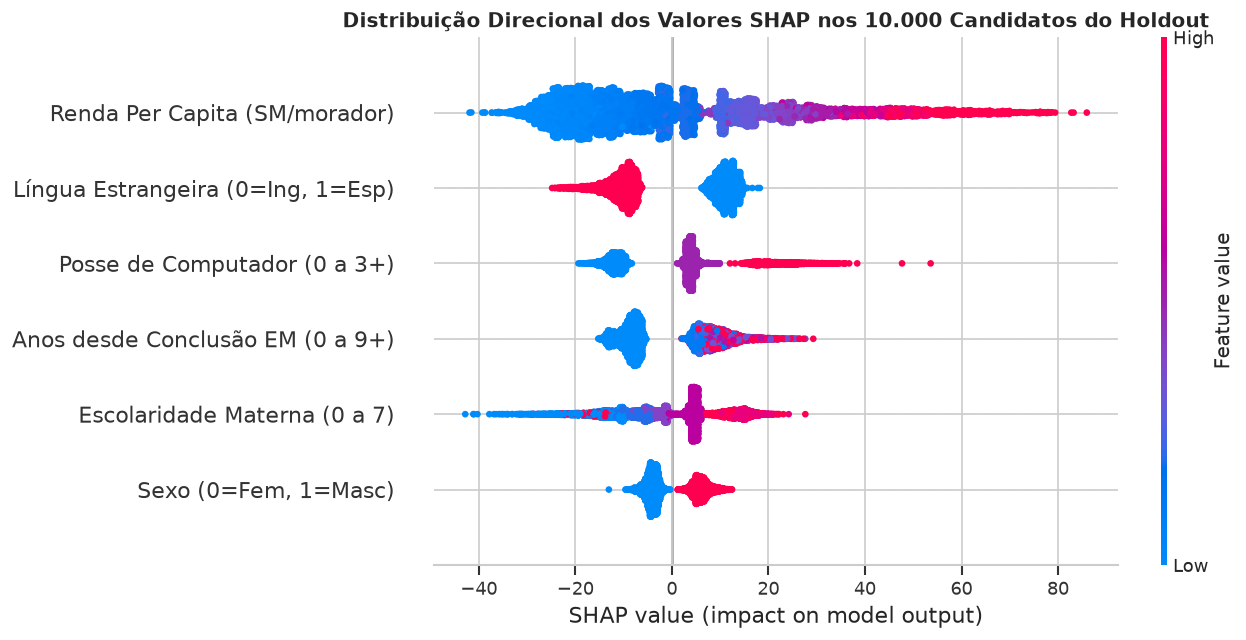

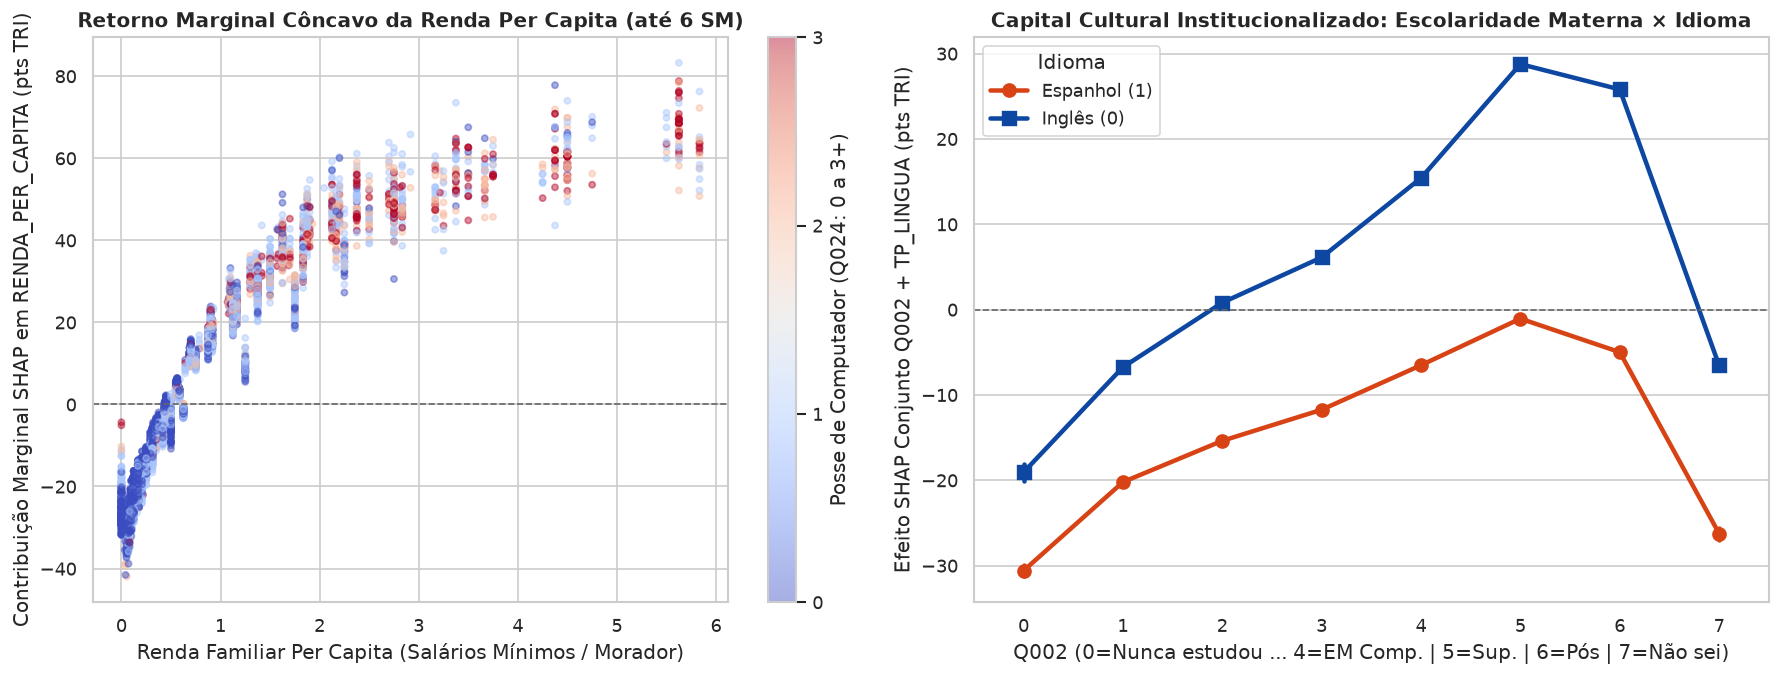

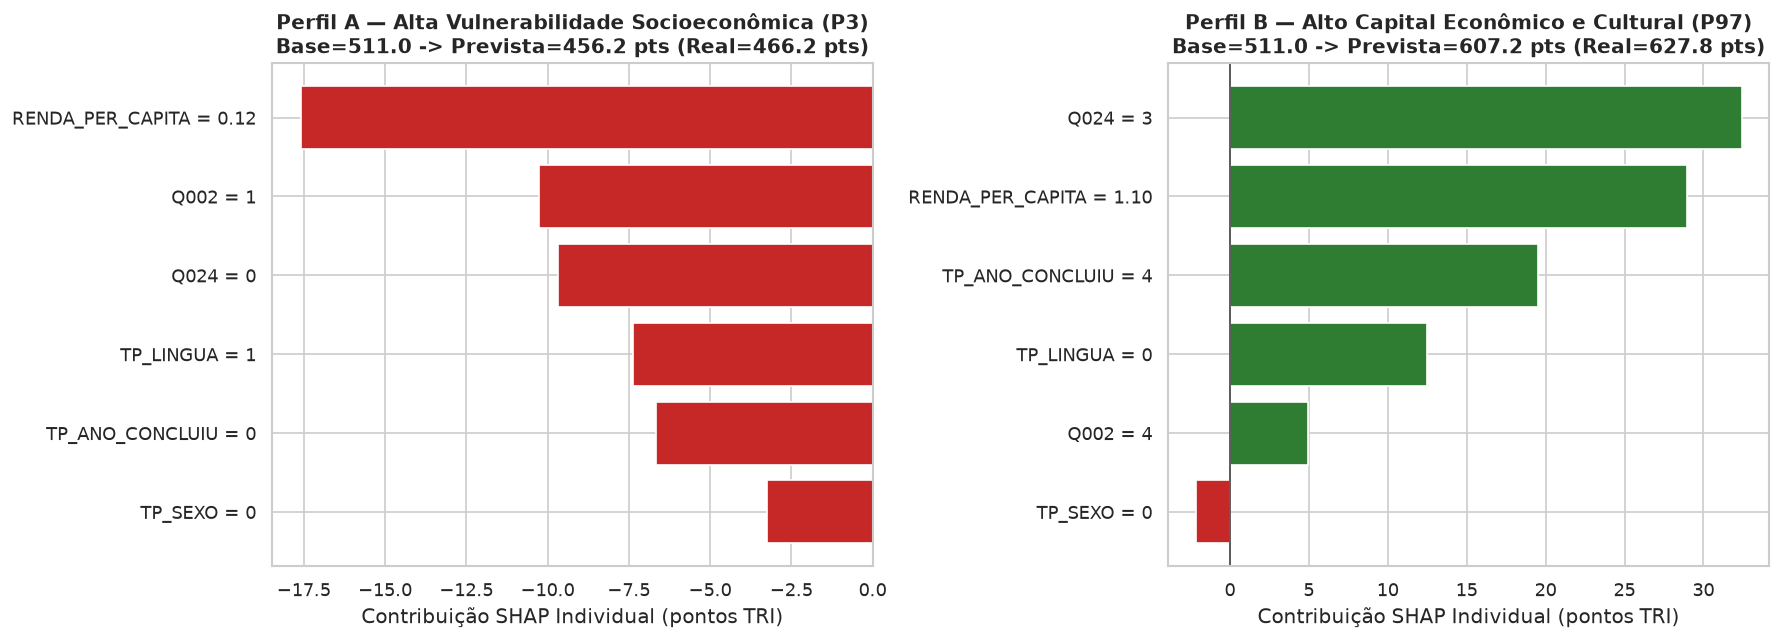

In [7]:
# ==============================================================================
# SEÇÃO 7: INTERPRETABILIDADE SOCIOLÓGICA VIA TREESHAP EXATO (BOURDIEU EM NÚMEROS)
# ==============================================================================
t0_shap = time.perf_counter()

# ── Bloco 7.1: Amostragem estratificada cega (1.000 alunos/ano = 10.000 do Holdout) ─
N_POR_ANO_SHAP = 1_000
partes_shap_idx = []
vetor_anos_holdout = df_test[COLUNA_PARTICAO_TEMPORAL].to_numpy()

for ano in ANOS_HOMOLOGADOS:
    idx_a = np.flatnonzero(vetor_anos_holdout == ano)
    partes_shap_idx.append(rng.choice(idx_a, size=min(N_POR_ANO_SHAP, len(idx_a)), replace=False))

idx_shap = np.concatenate(partes_shap_idx)
df_shap_full = df_test.iloc[idx_shap].reset_index(drop=True)
X_shap = df_shap_full[FEATURES_ELITE].copy()
y_shap_real = df_shap_full[ALVO_OFICIAL].to_numpy(dtype=np.float32)

explainer = shap.TreeExplainer(modelo_campeao)
explicacao_shap = explainer(X_shap)

valores_shap = np.asarray(explicacao_shap.values, dtype=np.float64)
if valores_shap.ndim == 3:
    valores_shap = valores_shap[..., 0]
valor_base_raw = np.asarray(explicacao_shap.base_values, dtype=np.float64).squeeze()
valor_base_escalar = float(np.mean(valor_base_raw))

# ── Bloco 7.2: Verificação matemática da Propriedade de Aditividade de Shapley ─
pred_shap_modelo = np.asarray(modelo_campeao.predict(X_shap), dtype=np.float64).reshape(-1)
soma_aditiva_shap = valor_base_raw + valores_shap.sum(axis=1)
erro_max_aditividade = float(np.max(np.abs(soma_aditiva_shap - pred_shap_modelo)))
assert erro_max_aditividade < 0.05, f"Violação de aditividade SHAP: {erro_max_aditividade}"

impacto_medio_abs = np.mean(np.abs(valores_shap), axis=0)
impacto_pct = 100.0 * impacto_medio_abs / np.sum(impacto_medio_abs)

df_ranking_shap = (
    pd.DataFrame({
        "Feature": FEATURES_ELITE,
        "Descrição Sociológica": [ROTULOS_FEATURES[f] for f in FEATURES_ELITE],
        "|SHAP| Médio (pts TRI)": np.round(impacto_medio_abs, 3),
        "Participação Relativa (%)": np.round(impacto_pct, 2),
        "Min SHAP (pts)": np.round(np.min(valores_shap, axis=0), 2),
        "Max SHAP (pts)": np.round(np.max(valores_shap, axis=0), 2),
    })
    .sort_values("|SHAP| Médio (pts TRI)", ascending=False)
    .reset_index(drop=True)
)

print("=" * 96)
print(
    f"AUDITORIA SHAP CONCLUÍDA EM {time.perf_counter() - t0_shap:.2f}s | "
    f"VALOR BASE E[f(X)] = {valor_base_escalar:.2f} PTS | ERRO ADITIVIDADE MÁX = {erro_max_aditividade:.2e}"
)
print("=" * 96)
display(df_ranking_shap)

# ── Bloco 7.3: Figuras Globais SHAP (Importância em Pontos TRI e Beeswarm) ─────
fig_bar, ax_bar = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=df_ranking_shap,
    x="|SHAP| Médio (pts TRI)",
    y="Descrição Sociológica",
    hue="Descrição Sociológica",
    palette="viridis",
    legend=False,
    ax=ax_bar,
)
ax_bar.set_title("Hierarquia do Determinismo Socioeconômico — Impacto Marginal Médio (|SHAP| em Pontos TRI)")
ax_bar.set_xlim(0, df_ranking_shap["|SHAP| Médio (pts TRI)"].max() * 1.18)
for idx_r, row_r in df_ranking_shap.iterrows():
    ax_bar.text(
        row_r["|SHAP| Médio (pts TRI)"] + 0.4,
        idx_r,
        f"{row_r['|SHAP| Médio (pts TRI)']:.2f} pts ({row_r['Participação Relativa (%)']:.1f}%)",
        va="center",
        fontweight="bold",
    )
plt.tight_layout()
caminho_fig_shap_bar = FIGURES_DIR / "04a_shap_importancia_barras.png"
fig_bar.savefig(caminho_fig_shap_bar, bbox_inches="tight")
plt.show()

# Beeswarm com nomes legíveis em português
explicacao_legivel = shap.Explanation(
    values=valores_shap,
    base_values=valor_base_raw,
    data=X_shap.to_numpy(),
    feature_names=[ROTULOS_FEATURES[c] for c in FEATURES_ELITE],
)
plt.figure(figsize=(11, 5.5))
shap.plots.beeswarm(explicacao_legivel, max_display=6, plot_size=(11, 5.5), show=False)
plt.title("Distribuição Direcional dos Valores SHAP nos 10.000 Candidatos do Holdout", fontweight="bold")
plt.tight_layout()
caminho_fig_shap_bee = FIGURES_DIR / "04b_shap_beeswarm.png"
plt.savefig(caminho_fig_shap_bee, bbox_inches="tight")
plt.show()

# ── Bloco 7.4: Interações Não-Lineares de Bourdieu + Perfis Contrastantes ──────
idx_rpc = FEATURES_ELITE.index("RENDA_PER_CAPITA")
idx_q024 = FEATURES_ELITE.index("Q024")
idx_q002 = FEATURES_ELITE.index("Q002")
idx_ling = FEATURES_ELITE.index("TP_LINGUA")

fig_int, axes_int = plt.subplots(1, 2, figsize=(15, 5.8))

# Painel Esquerdo: Renda Per Capita (SM) × Posse de Computador (Q024)
rpc_vals = X_shap["RENDA_PER_CAPITA"].to_numpy()
mask_zoom_rpc = rpc_vals <= 6.0  # Concentra >98% dos candidatos para visualização nítida da curvatura
scatter_rpc = axes_int[0].scatter(
    rpc_vals[mask_zoom_rpc],
    valores_shap[mask_zoom_rpc, idx_rpc],
    c=X_shap["Q024"].to_numpy()[mask_zoom_rpc],
    cmap="coolwarm",
    alpha=0.45,
    s=14,
    rasterized=True,
)
cbar_int = plt.colorbar(scatter_rpc, ax=axes_int[0], ticks=[0, 1, 2, 3])
cbar_int.set_label("Posse de Computador (Q024: 0 a 3+)")
axes_int[0].axhline(0, color="#666666", linestyle="--", linewidth=1)
axes_int[0].set_title("Retorno Marginal Côncavo da Renda Per Capita (até 6 SM)")
axes_int[0].set_xlabel("Renda Familiar Per Capita (Salários Mínimos / Morador)")
axes_int[0].set_ylabel("Contribuição Marginal SHAP em RENDA_PER_CAPITA (pts TRI)")

# Painel Direito: Escolaridade da Mãe (Q002) × Língua Estrangeira (TP_LINGUA)
df_int_cult = pd.DataFrame({
    "Q002": X_shap["Q002"].to_numpy(),
    "SHAP_Cultural_Combinado": valores_shap[:, idx_q002] + valores_shap[:, idx_ling],
    "Idioma": np.where(X_shap["TP_LINGUA"].to_numpy() == 0, "Inglês (0)", "Espanhol (1)"),
})
sns.pointplot(
    data=df_int_cult,
    x="Q002",
    y="SHAP_Cultural_Combinado",
    hue="Idioma",
    palette={"Inglês (0)": "#0d47a1", "Espanhol (1)": "#d84315"},
    markers=["o", "s"],
    ax=axes_int[1],
)
axes_int[1].axhline(0, color="#666666", linestyle="--", linewidth=1)
axes_int[1].set_title("Capital Cultural Institucionalizado: Escolaridade Materna × Idioma")
axes_int[1].set_xlabel("Q002 (0=Nunca estudou ... 4=EM Comp. | 5=Sup. | 6=Pós | 7=Não sei)")
axes_int[1].set_ylabel("Efeito SHAP Conjunto Q002 + TP_LINGUA (pts TRI)")

plt.tight_layout()
caminho_fig_interacoes = FIGURES_DIR / "05_shap_interacoes_bourdieu.png"
fig_int.savefig(caminho_fig_interacoes, bbox_inches="tight")
plt.show()

# Decomposição individual de 2 perfis reais extremos da amostra cega
ordem_pred_shap = np.argsort(pred_shap_modelo)
idx_vulneravel = int(ordem_pred_shap[int(len(ordem_pred_shap) * 0.03)])   # Percentil 3%
idx_privilegiado = int(ordem_pred_shap[int(len(ordem_pred_shap) * 0.97)]) # Percentil 97%

fig_perf, axes_perf = plt.subplots(1, 2, figsize=(15, 5.5), sharex=False)
for ax_p, idx_cand, titulo_p in [
    (axes_perf[0], idx_vulneravel, "Perfil A — Alta Vulnerabilidade Socioeconômica (P3)"),
    (axes_perf[1], idx_privilegiado, "Perfil B — Alto Capital Econômico e Cultural (P97)"),
]:
    contribs = valores_shap[idx_cand]
    vals_cand = X_shap.iloc[idx_cand]
    nomes_barras = [
        f"{col} = {vals_cand[col]:.2f}" if col == "RENDA_PER_CAPITA" else f"{col} = {int(vals_cand[col])}"
        for col in FEATURES_ELITE
    ]
    ordem_c = np.argsort(np.abs(contribs))
    cores_c = ["#c62828" if contribs[j] < 0 else "#2e7d32" for j in ordem_c]

    ax_p.barh(
        [nomes_barras[j] for j in ordem_c],
        [contribs[j] for j in ordem_c],
        color=cores_c,
    )
    ax_p.axvline(0, color="#444444", linewidth=1)
    nota_prev_c = pred_shap_modelo[idx_cand]
    nota_real_c = y_shap_real[idx_cand]
    ax_p.set_title(
        f"{titulo_p}\nBase={valor_base_escalar:.1f} -> Prevista={nota_prev_c:.1f} pts (Real={nota_real_c:.1f} pts)"
    )
    ax_p.set_xlabel("Contribuição SHAP Individual (pontos TRI)")

plt.tight_layout()
caminho_fig_perfis = FIGURES_DIR / "06_shap_perfis_contrastantes.png"
fig_perf.savefig(caminho_fig_perfis, bbox_inches="tight")
plt.show()

---
## 8. Serialização de Produção (`models/enem.pkl`), *Model Card*, *MLflow Registry* e *Smoke Test*

### Como entregamos o modelo pronto para a Etapa 2 (FastAPI + Docker + AWS)?
Esta última seção consolida todos os entregáveis de MLOps em **4 blocos de produção**:
* **Bloco 8.1 (Serialização Universal de `models/enem.pkl`):** Salva o **estimador campeão puro** usando `pickle.HIGHEST_PROTOCOL` (formato binário universal que pode ser carregado tanto via `pickle.load()` quanto via `joblib.load()` no serviço FastAPI), além de exportar o binário nativo `models/enem_xgboost.ubj` e calcular seu hash `SHA-256`.
* **Bloco 8.2 (Contrato de Governança `models/enem_model_card.json`):** Documenta em JSON estruturado as versões de runtime, checksums `SHA-256`, especificação estrita das 6 features (tipos e limites de domínio prontos para validação `Pydantic` no endpoint `POST /predict`), métricas globais no Holdout de `7,52M`, métricas *Out-of-Time* em `2023`, métricas por ano e ranking SHAP.
* **Bloco 8.3 (Anexação de Artefatos e Registro no *MLflow Model Registry*):** Reabre a *Run* Campeã no MLflow para anexar todos os gráficos, tabelas e o *Model Card*, e registra formalmente o modelo sob o nome **`enem_target_m4_producao`** com assinatura (`ModelSignature`) validada.
* **Bloco 8.4 (*Smoke Test Round-Trip* de Produção):** Recarrega `models/enem.pkl` diretamente do disco (via `pickle` e `joblib`), simula payloads reais de inferência (tanto em tipos compactos `int8/float32` quanto nos tipos padrão `int64/float64` oriundos de JSON HTTP) e confirma igualdade numérica absoluta.

In [8]:
# ==============================================================================
# SEÇÃO 8: SERIALIZAÇÃO (enem.pkl), MODEL CARD, MLFLOW REGISTRY E SMOKE TEST
# ==============================================================================
t0_serial = time.perf_counter()

# ── Bloco 8.1: Serialização do estimador campeão puro em models/enem.pkl ───────
with open(CAMINHO_MODELO_PKL, "wb") as f_pkl:
    pickle.dump(modelo_campeao, f_pkl, protocol=pickle.HIGHEST_PROTOCOL)

if isinstance(modelo_campeao, XGBRegressor):
    modelo_campeao.save_model(CAMINHO_MODELO_UBJ)

sha256_modelo_pkl = hashlib.sha256(CAMINHO_MODELO_PKL.read_bytes()).hexdigest()
tamanho_pkl_mb = round(CAMINHO_MODELO_PKL.stat().st_size / (1024 ** 2), 3)

# ── Bloco 8.2: Construção do Model Card e Contrato de Inferência FastAPI ───────
model_card = {
    "nome_artefato": "enem.pkl",
    "caminho_relativo": "models/enem.pkl",
    "modelo_registrado_mlflow": MLFLOW_REGISTERED_MODEL_NAME,
    "mlflow_run_id_campeao": campeao_run_id,
    "data_treinamento_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "classe_modelo_campeao": nome_campeao,
    "sha256_enem_pkl": sha256_modelo_pkl,
    "tamanho_disco_mb": tamanho_pkl_mb,
    "linhagem_dados": {
        "parquet_origem": "data/processed/enem_2014_2023_consolidado.parquet",
        "sha256_parquet_origem": sha256_calculado,
        "janela_historica": "2014-2023",
        "n_total_censo": int(n_total_decada),
        "n_holdout_cego": int(len(df_test)),
    },
    "ambiente_treinamento": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "xgboost": xgb.__version__,
        "mlflow": mlflow.__version__,
        "shap": shap.__version__,
    },
    "contrato_inferencia_api": {
        "alvo": ALVO_OFICIAL,
        "unidade_alvo": "pontos_escala_tri_0_a_1000",
        "features_ordenadas": FEATURES_ELITE,
        "especificacao_campos": {
            "RENDA_PER_CAPITA": {"tipo": "float", "min": 0.0, "max": 25.0, "descricao": ROTULOS_FEATURES["RENDA_PER_CAPITA"]},
            "Q024": {"tipo": "int", "valores_validos": [0, 1, 2, 3], "descricao": ROTULOS_FEATURES["Q024"]},
            "TP_ANO_CONCLUIU": {"tipo": "int", "valores_validos": list(range(0, 10)), "descricao": ROTULOS_FEATURES["TP_ANO_CONCLUIU"]},
            "TP_LINGUA": {"tipo": "int", "valores_validos": [0, 1], "descricao": ROTULOS_FEATURES["TP_LINGUA"]},
            "TP_SEXO": {"tipo": "int", "valores_validos": [0, 1], "descricao": ROTULOS_FEATURES["TP_SEXO"]},
            "Q002": {"tipo": "int", "valores_validos": list(range(0, 8)), "descricao": ROTULOS_FEATURES["Q002"]},
        },
    },
    "metricas_oficiais": {
        "holdout_estratificado_7_52m": metricas_campeao,
        "out_of_time_interno_2014_2022_para_2023": {
            **metricas_oot_2023,
            "vies_medio_pts": vies_oot_2023,
        },
        "desempenho_por_ano_holdout": metricas_anuais_lista,
    },
    "explicabilidade_shap": {
        "valor_base_esperado_tri": round(valor_base_escalar, 4),
        "n_amostras_holdout_shap": int(len(X_shap)),
        "ranking_global": df_ranking_shap.to_dict(orient="records"),
    },
}

with open(CAMINHO_MODEL_CARD, "w", encoding="utf-8") as f_mc:
    json.dump(model_card, f_mc, indent=2, ensure_ascii=False)

# ── Bloco 8.3: Registro no MLflow Model Registry e anexação de artefatos ───────
exemplo_entrada_api = pd.DataFrame(
    [
        {"RENDA_PER_CAPITA": 0.25, "Q024": 0, "TP_ANO_CONCLUIU": 1, "TP_LINGUA": 1, "TP_SEXO": 0, "Q002": 2},
        {"RENDA_PER_CAPITA": 3.50, "Q024": 3, "TP_ANO_CONCLUIU": 0, "TP_LINGUA": 0, "TP_SEXO": 1, "Q002": 6},
    ]
)[FEATURES_ELITE].astype({"RENDA_PER_CAPITA": "float64", "Q024": "int64", "TP_ANO_CONCLUIU": "int64", "TP_LINGUA": "int64", "TP_SEXO": "int64", "Q002": "int64"})

pred_exemplo = np.asarray(modelo_campeao.predict(exemplo_entrada_api), dtype=np.float32)
assinatura_mlflow = infer_signature(exemplo_entrada_api, pred_exemplo)

with mlflow.start_run(run_id=campeao_run_id):
    mlflow.set_tag("campeao_producao", "true")
    mlflow.log_metric("shap_valor_base_tri", round(valor_base_escalar, 4))
    mlflow.log_metric("tamanho_enem_pkl_mb", tamanho_pkl_mb)

    for arq_artefato in [
        caminho_fig_bench,
        caminho_fig_anual,
        caminho_fig_shap_bar,
        caminho_fig_shap_bee,
        caminho_fig_interacoes,
        caminho_fig_perfis,
        caminho_csv_anual,
        CAMINHO_MODEL_CARD,
    ]:
        if Path(arq_artefato).exists():
            mlflow.log_artifact(str(arq_artefato), artifact_path="relatorio_auditoria_tcc")

    if isinstance(modelo_campeao, XGBRegressor):
        info_registro = mlflow.xgboost.log_model(
            xgb_model=modelo_campeao,
            name="modelo_campeao_enem",
            registered_model_name=MLFLOW_REGISTERED_MODEL_NAME,
            signature=assinatura_mlflow,
            input_example=exemplo_entrada_api,
        )
    else:
        info_registro = mlflow.sklearn.log_model(
            sk_model=modelo_campeao,
            name="modelo_campeao_enem",
            registered_model_name=MLFLOW_REGISTERED_MODEL_NAME,
            signature=assinatura_mlflow,
            input_example=exemplo_entrada_api,
        )

# ── Bloco 8.4: Smoke Test Round-Trip de Produção (pickle + joblib + JSON API) ─
with open(CAMINHO_MODELO_PKL, "rb") as f_in:
    modelo_via_pickle = pickle.load(f_in)
modelo_via_joblib = joblib.load(CAMINHO_MODELO_PKL)

amostra_compacta = df_test.iloc[:100][FEATURES_ELITE]
pred_ref = np.asarray(modelo_campeao.predict(amostra_compacta), dtype=np.float32)
pred_pkl = np.asarray(modelo_via_pickle.predict(amostra_compacta), dtype=np.float32)
pred_jbl = np.asarray(modelo_via_joblib.predict(amostra_compacta), dtype=np.float32)

assert np.allclose(pred_ref, pred_pkl, atol=1e-5), "Divergência na desserialização via pickle!"
assert np.allclose(pred_ref, pred_jbl, atol=1e-5), "Divergência na desserialização via joblib!"

# Simula exatamente um JSON chegando no endpoint POST /predict do FastAPI (tipos int64/float64 padrão)
pred_json_fastapi = np.asarray(modelo_via_joblib.predict(exemplo_entrada_api), dtype=np.float32)
assert np.all((pred_json_fastapi >= 0.0) & (pred_json_fastapi <= 1000.0))

df_simulacao_api = exemplo_entrada_api.copy()
df_simulacao_api["TARGET_M4_PREVISTO"] = np.round(pred_json_fastapi, 2)

ram_final = obter_telemetria_ram()
print("=" * 96)
print("NOTEBOOK 06 CONCLUÍDO COM SUCESSO — MODELO DE PRODUÇÃO HOMOLOGADO E REGISTRADO!")
print("=" * 96)
print(f"• Artefato Principal      : {CAMINHO_MODELO_PKL} ({tamanho_pkl_mb:.3f} MB)")
print(f"• Checksum SHA-256        : {sha256_modelo_pkl}")
print(f"• Model Card & Contrato   : {CAMINHO_MODEL_CARD}")
print(f"• Modelo no MLflow        : {MLFLOW_REGISTERED_MODEL_NAME} (URI={info_registro.model_uri})")
print(f"• Métricas Finais Holdout : R²={metricas_campeao['r2']:.5f} | RMSE={metricas_campeao['rmse']:.4f} pts | MAE={metricas_campeao['mae']:.4f} pts")
print(f"• Smoke Test (API FastAPI): APROVADO (compatível com pickle.load, joblib.load e tipos JSON)")
print(f"• Telemetria Final RAM    : Processo={ram_final['processo_rss_mb']:.1f} MB | Livre={ram_final['sistema_disponivel_gb']:.2f} GB")
print("-" * 96)
print("Para inspecionar todos os experimentos, curvas e artefatos no navegador, execute no terminal:")
print(f"   mlflow ui --backend-store-uri {MLFLOW_TRACKING_URI} --port 5000")
print("=" * 96)
display(df_simulacao_api)

2026/11/03 09:36:45 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Successfully registered model 'enem_target_m4_producao'.
Created version '1' of model 'enem_target_m4_producao'.


NOTEBOOK 06 CONCLUÍDO COM SUCESSO — MODELO DE PRODUÇÃO HOMOLOGADO E REGISTRADO!
• Artefato Principal      : /home/saulo/mba/tcc/enem/models/enem.pkl (1.727 MB)
• Checksum SHA-256        : 114f51959492c89a240f9a64adb5d1365cf7c255b1b95a4cb8510636019bd55f
• Model Card & Contrato   : /home/saulo/mba/tcc/enem/models/enem_model_card.json
• Modelo no MLflow        : enem_target_m4_producao (URI=models:/m-de46630bf79d477288f7176b47c76bad)
• Métricas Finais Holdout : R²=0.33780 | RMSE=57.7439 pts | MAE=45.5904 pts
• Smoke Test (API FastAPI): APROVADO (compatível com pickle.load, joblib.load e tipos JSON)
• Telemetria Final RAM    : Processo=2263.2 MB | Livre=4.26 GB
------------------------------------------------------------------------------------------------
Para inspecionar todos os experimentos, curvas e artefatos no navegador, execute no terminal:
   mlflow ui --backend-store-uri sqlite:////home/saulo/mba/tcc/enem/mlflow.db --port 5000


,RENDA_PER_CAPITA,Q024,TP_ANO_CONCLUIU,TP_LINGUA,TP_SEXO,Q002,TARGET_M4_PREVISTO
0,0.25,0,1,1,0,2,476.079987
1,3.50,3,0,0,1,6,612.260010
